# Topik 1 — Windowing & STFT pada Suara Burung Hama Padi
**Notebook Jupyter (dijalankan lokal, mis. di Antigravity/VS Code) · Kelompok 1 · Sinyal dan Sistem**

Notebook ini adalah versi `.ipynb` dari skrip `topik1_stft.py`. Isi kodenya sama; yang berubah hanya cara menjalankannya (per sel, bukan lewat terminal) dan ditambah penjelasan di setiap bagian.

## Peta empat kategori → bagian kode

| Kategori | Butir | Fungsi / baris kode yang membuktikannya | Keluaran |
|---|---|---|---|
| **A. Kesiapan data** (Minggu 1) | Data terunduh | `scan_wavs()` → `sf.info(...)` membaca setiap `.wav` | `A0_file_rusak.csv` (jika ada), `A1b_daftar_file.csv` |
| | fs tercatat | `scan_wavs()` → `sr=info.samplerate`; ringkasan di `A_data()` (`df.sr.value_counts()`) | `A2_inventaris.csv`, `A2b_fs_per_kelas.csv` |
| | Jumlah klip per kelas | `A_data()` → `pd.crosstab(df["label"], df["split"])` | `A1_jumlah_klip.csv` |
| | 5 fold tersusun | `make_folds()` → `StratifiedKFold(...)` | `A4_fold_per_klip.csv`, `A5_fold_per_kelas.csv` |
| **B. Praproses dan kode** (Minggu 1) | Pre-emphasis | `load_preemph()` → `np.append(y[0], y[1:] - a * y[:-1])` | `F_konfigurasi_eksperimen.json` (nilai 0,97) |
| | Bandpass | `make_filters()` (membuat filter) dan `apply_filter()` (menerapkan) | `B1_respons_filter.png`, `E1_snr.csv` |
| | Skrip fitur | `clip_features()`, `clip_all()`, `stream()` | `fitur_*.npz` |
| **C. Eksperimen inti** (Minggu 2) | 16 konfigurasi window | `WIN_SIZES`, `WIN_TYPES`, `C_core()` | `C1`–`C4`, `fitur_*.npz` |
| **D. Validasi dan uji statistik** (Minggu 2) | 5-fold × 3 seed, Friedman + Nemenyi | `D_validation()` → `friedmanchisquare`, `posthoc_nemenyi_friedman` | `D1`–`D3` |
| | Asumsi dicek, ukuran efek dilaporkan | Bagian **D.2**: `sensitivitas()`, `kendall_w()`, `nemenyi_cd()`, `efek_berpasangan()` | `D4`–`D6` |

## Cara memakai secara lokal
1. Simpan notebook ini **di folder yang sama dengan `training/` dan `testing/`** (misalnya `bird_sounds/`).
2. Pilih kernel Python dari `.venv` proyekmu (pojok kanan atas notebook).
3. Jalankan sel dari atas ke bawah (Shift+Enter, atau **Run All**).
4. Semua hasil (CSV, PNG, JSON, NPZ) disimpan di folder `hasil/` di sebelah `training/` dan `testing/`.


## 0. Persiapan (pustaka, lokasi data, pengaturan)

In [35]:
# ====================================================================================
# SEL #3  |  PERSIAPAN
# FUNGSI : Memeriksa pustaka Python yang dibutuhkan dan memasang yang belum ada.
# OUTPUT : Hanya pesan teks ('Semua pustaka sudah terpasang.'). Tidak ada file.
# LIHAT  : Output teks tepat di bawah sel ini.
# ====================================================================================
# Pasang pustaka yang belum ada di kernel (hanya memasang jika belum terpasang)
import importlib.util, sys
butuh = {"librosa": "librosa", "soundfile": "soundfile", "sklearn": "scikit-learn", "seaborn": "seaborn",
         "scikit_posthocs": "scikit-posthocs", "joblib": "joblib", "pandas": "pandas", "matplotlib": "matplotlib", "scipy": "scipy"}
kurang = [pip_name for mod, pip_name in butuh.items() if importlib.util.find_spec(mod) is None]
if kurang:
    print("Memasang:", kurang)
    %pip install -q {" ".join(kurang)}
    print("Selesai. Jika muncul error import di sel berikutnya, restart kernel lalu jalankan ulang.")
else:
    print("Semua pustaka sudah terpasang.")

Semua pustaka sudah terpasang.


In [36]:
# ====================================================================================
# SEL #4  |  PERSIAPAN
# FUNGSI : Pengaturan: lokasi data (DATA_ROOT), mode penuh/cepat (FULL), JOBS. Folder
#          training/ dan testing/ diperiksa di sini.
# OUTPUT : Pesan teks: 'Folder data' dan 'Folder hasil'. Tidak ada file.
# LIHAT  : Output teks di bawah sel ini. Folder hasil = DATA_ROOT/hasil.
# ====================================================================================
from pathlib import Path

# ---------------- PENGATURAN YANG BOLEH KAMU UBAH ----------------
# Folder yang berisi training/ dan testing/. Bawaan: folder tempat notebook ini disimpan.
# Jika notebook berada di tempat lain, isi manual, contoh:
# DATA_ROOT = Path(r"D:\TUGAS\SEMESTER 5\Sinyal dan Sistem\UAS Kelompok\bird_sounds")
DATA_ROOT = Path.cwd()
FULL   = True     # True = semua klip (8.512). False = uji cepat (300 klip/kelas training, 100 testing)
MERGE6 = False    # opsional: gabungkan label Bulbul & Chubbs_cis ke Other_Birds
JOBS   = 1        # proses paralel. 1 = paling aman untuk memori; naikkan ke 2-4 jika RAM besar
# -------------------------------------------------------------------

OUT_DIR = DATA_ROOT / "hasil"            # semua luaran disimpan di sini
for split in ("training", "testing"):
    assert (DATA_ROOT / split).is_dir(), f"Folder {DATA_ROOT / split} tidak ditemukan. Atur DATA_ROOT di atas."
print("Folder data  :", DATA_ROOT)
print("Folder hasil :", OUT_DIR)

Folder data  : d:\TUGAS\SEMESTER 5\Sinyal dan Sistem\UAS Kelompok\bird_sounds
Folder hasil : d:\TUGAS\SEMESTER 5\Sinyal dan Sistem\UAS Kelompok\bird_sounds\hasil


In [37]:
# ====================================================================================
# SEL #5  |  PERSIAPAN
# FUNGSI : Memuat semua pustaka, dan mendefinisikan 16 KONFIGURASI: WIN_SIZES (4
#          ukuran) x WIN_TYPES (4 jenis window).
# OUTPUT : Tidak ada output (hanya mendefinisikan variabel dan impor).
# LIHAT  : Konstanta WIN_SIZES/WIN_TYPES dipakai di sel 44 (C) dan 49
#          (D).
# ====================================================================================
import os
for _v in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "1")          # hemat memori: tiap proses paralel hanya 1 thread BLAS
import json, platform, time, warnings
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import librosa, librosa.display
import soundfile as sf
import scipy, sklearn
import scikit_posthocs as sp
from joblib import Parallel, delayed
from scipy import signal
from scipy.stats import friedmanchisquare, wilcoxon
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore")

WIN_SIZES = [256, 512, 1024, 2048]


WIN_TYPES = ["boxcar", "hann", "hamming", "blackman"]      # boxcar = rectangular


NICE = {"boxcar": "Rectangular", "hann": "Hann", "hamming": "Hamming", "blackman": "Blackman"}

### Konfigurasi dan fungsi bantu
Di skrip asli, pengaturan dibaca dari terminal lewat `argparse` (`get_args()`). Di notebook, pengaturan itu diganti dengan fungsi `make_cfg()` yang isinya sama (nilai bawaan tidak berubah). Fungsi `savefig()` juga ditambah `plt.show()` supaya gambar langsung tampil di notebook.

In [38]:
# ====================================================================================
# SEL #7  |  PERSIAPAN
# FUNGSI : Membuat objek cfg berisi semua parameter eksperimen (fs target 22050,
#          folds=5, seeds=0/1/2, pre-emphasis 0,97, bandpass 1-10 kHz, dll.) serta
#          fungsi bantu savefig/save_table/title.
# OUTPUT : Tidak ada output langsung. Fungsi savefig() menyimpan gambar ke hasil/ dan
#          menampilkannya.
# LIHAT  : cfg dibuat di sel 8.
# ====================================================================================
def make_cfg(data_root, out_dir, full=True, merge6=False, jobs=1, sub_train=300, sub_test=100,
             sr=22050, hop_ratio=0.5, folds=5, seeds=(0, 1, 2), fir_taps=129, max_dur=3.0, seed=42):
    """Pengganti get_args(): semua parameter eksperimen dikumpulkan di satu objek `cfg`."""
    a = SimpleNamespace(data_root=Path(data_root), sub_train=sub_train, sub_test=sub_test, full=full,
                        merge6=merge6, sr=sr, hop_ratio=hop_ratio, folds=folds, seeds=list(seeds),
                        fir_taps=fir_taps, jobs=jobs, max_dur=max_dur, seed=seed)
    if a.full:
        a.sub_train = a.sub_test = None
    a.preemph, a.bp_low, a.bp_high = 0.97, 1000, 10000     # pre-emphasis 0,97; bandpass 1-10 kHz
    a.out = Path(out_dir)
    a.out.mkdir(parents=True, exist_ok=True)
    return a


def parallel(cfg, tasks, batch_size="auto"):
    """Jalankan tugas joblib; jika proses paralel gagal (mis. memori Windows habis) ulangi dengan 1 proses."""
    if cfg.jobs == 1:
        return Parallel(n_jobs=1)(tasks)         # generator diproses satu per satu (hemat memori)
    tasks = list(tasks)
    try:
        return Parallel(n_jobs=cfg.jobs, batch_size=batch_size)(tasks)
    except Exception as e:
        print(f"  PERINGATAN: paralel gagal ({type(e).__name__}); mengulang dengan 1 proses (lebih lambat tapi aman).")
        return Parallel(n_jobs=1)(tasks)


def savefig(cfg, name):
    plt.tight_layout()
    plt.savefig(cfg.out / name, dpi=150, bbox_inches="tight")
    plt.show()                      # tampilkan di notebook
    plt.close("all")
    print(f"  [gambar] {name}")


def save_table(cfg, df, name, index=True):
    df.to_csv(cfg.out / name, index=index)
    print(f"  [tabel]  {name}")


def title(t):
    print("\n" + "=" * 78 + f"\n{t}\n" + "=" * 78)

In [39]:
# ====================================================================================
# SEL #8  |  PERSIAPAN
# FUNGSI : Menjalankan make_cfg() sehingga cfg siap dipakai semua bagian A-F.
# OUTPUT : Mencetak isi cfg (semua parameter). Tidak ada file.
# LIHAT  : Output teks di bawah sel ini.
# ====================================================================================
cfg = make_cfg(DATA_ROOT, OUT_DIR, full=FULL, merge6=MERGE6, jobs=JOBS)
np.random.seed(cfg.seed)
print(cfg)

namespace(data_root=WindowsPath('d:/TUGAS/SEMESTER 5/Sinyal dan Sistem/UAS Kelompok/bird_sounds'), sub_train=None, sub_test=None, full=True, merge6=False, sr=22050, hop_ratio=0.5, folds=5, seeds=[0, 1, 2], fir_taps=129, jobs=1, max_dur=3.0, seed=42, preemph=0.97, bp_low=1000, bp_high=10000, out=WindowsPath('d:/TUGAS/SEMESTER 5/Sinyal dan Sistem/UAS Kelompok/bird_sounds/hasil'))


---
# A. Kesiapan Data (Minggu 1)
**Butir yang diminta:** data terunduh · fs dan jumlah klip per kelas tercatat · 5 fold tersusun.

Bagian ini terdiri dari lima fungsi. Berikut kode mana yang menjawab butir yang mana.

### A.1 Bagaimana kelas ditentukan? → `label_from_filename()`
Kelas diambil dari **nama file**, yaitu teks sebelum titik pertama. Contoh: `Noise.0001.wav` → `Noise`.
Folder `training/` dan `testing/` hanya menentukan **split** (latih atau uji), bukan kelas.

Daftar kelas final dibuat di `A_data()`: `classes = sorted(d.label.unique())` (urut abjad, supaya nomor kelas 0–5 selalu sama).

In [40]:
# ====================================================================================
# SEL #11  |  A. KESIAPAN DATA
# FUNGSI : Menentukan KELAS dari nama file (label_from_filename) dan subsampling untuk
#          uji cepat.
# OUTPUT : Tidak ada output langsung (hanya mendefinisikan fungsi).
# LIHAT  : Dipakai oleh scan_wavs (sel 13). Hasil kelas terlihat di sel
#          21 dan tabel A1 di sel 23.
# ====================================================================================
def stratified_subsample(d, n, seed):
    """Ambil maksimal n klip per kelas (dipakai hanya untuk uji cepat; --full mematikan ini)."""
    # mode penuh (--full): tidak ada subsampling
    if n is None:
        return d
    # ambil acak maks. n klip per kelas (hanya untuk uji cepat)
    return pd.concat([g.sample(min(len(g), n), random_state=seed) for _, g in d.groupby("label")])


def label_from_filename(path):
    """
    CARA KODE MENENTUKAN KELAS.
    Kelas diambil dari NAMA FILE: teks sebelum titik pertama.
        'Noise.0001.wav'          -> 'Noise'
        'VillageWeaver.xyz.wav'   -> 'VillageWeaver'
    Folder training/ dan testing/ hanya menentukan SPLIT (latih atau uji), bukan kelasnya.
    Daftar kelas final = semua label unik yang ditemukan, diurutkan abjad (lihat A_data).
    """
    # KELAS = teks sebelum titik pertama pada nama file
    return Path(path).name.split(".")[0]

### A.2 **Data terunduh** dan **fs tercatat** → `scan_wavs()`
- **Data terunduh:** fungsi ini memindai seluruh `.wav` di `training/` dan `testing/`. Baris kuncinya `info = sf.info(str(p))` membaca header tiap file. Jika file rusak, ia dicatat di `skipped` dan dilewati, jadi program tidak berhenti.
- **fs tercatat:** baris `sr=info.samplerate` menyimpan sampling rate asli tiap file. Durasi (`dur`) dan jumlah kanal (`ch`) dicatat bersamaan.

`sf.info()` hanya membaca header, bukan seluruh sinyal, jadi memindai 8.512 file tetap cepat dan hemat memori.

In [ ]:
# ====================================================================================
# SEL #13  |  A. KESIAPAN DATA
# FUNGSI : DATA TERUNDUH + fs TERCATAT: memindai semua .wav di training/ dan testing/,
#          membaca header tiap file (fs, durasi, kanal) dan label.
# OUTPUT : Tidak ada output langsung. Mengembalikan daftar file (rows) dan file rusak
#          (skipped).
# LIHAT  : Dipanggil di A_data (sel 19), dijalankan di sel 21. Hasil:
#          hasil/A2_inventaris.csv, hasil/A1b_daftar_file.csv (lihat sel
#          24).
# ====================================================================================
def scan_wavs(cfg):
    """Langkah 1-2: pindai semua .wav, baca header (fs, durasi, kanal) TANPA memuat sinyalnya."""
    # rows: info semua file; skipped: file yang gagal dibaca
    rows, skipped = [], []
    for split in ("training", "testing"):                    # hanya dua folder ini (abaikan .venv, hasil, dll.)
        folder = cfg.data_root / split
        if not folder.is_dir():
            print(f"PERINGATAN: folder {folder} tidak ditemukan")
            continue
        # telusuri semua file .wav di folder ini
        for p in sorted(folder.rglob("*.wav")):
            try:
                #bagian yang membaca dan mencatat nilai fs
                info = sf.info(str(p))                       # membaca header saja -> cepat dan hemat memori
            except Exception as e:                           # file rusak: catat, lewati, jangan hentikan program
                skipped.append(dict(file=str(p), error=type(e).__name__)); continue
            # catat: path, split (nama folder), label (dari nama file)
            rows.append(dict(path=str(p), split=split, label=label_from_filename(p),
                             # sr = fs ASLI file (Hz), inilah 'fs tercatat'; juga durasi dan jumlah
                             #   kanal
                             sr=info.samplerate, dur=info.duration, ch=info.channels))
    # dikembalikan ke A_data
    return rows, skipped

### A.3 Validasi label → `check_labels()`
Pengaman agar salah baca nama file ketahuan sejak awal: kelas training dan testing harus sama, jumlah kelas tidak boleh terlalu banyak, dan kelas terkecil harus punya cukup klip untuk dibagi menjadi 5 fold.

In [42]:
# ====================================================================================
# SEL #15  |  A. KESIAPAN DATA
# FUNGSI : Memvalidasi label: kelas training dan testing sama, jumlah kelas wajar,
#          kelas terkecil cukup untuk 5 fold.
# OUTPUT : Tidak ada output kalau semua beres. Jika ada masalah: peringatan atau
#          error.
# LIHAT  : Dipanggil di A_data, dijalankan di sel 21.
# ====================================================================================
def check_labels(df, cfg):
    """Langkah 3: validasi label supaya salah baca nama file ketahuan sejak awal."""
    # himpunan kelas di training vs testing (harus sama)
    lab_tr, lab_te = set(df[df.split == "training"].label), set(df[df.split == "testing"].label)
    if lab_tr != lab_te:
        print(f"PERINGATAN: kelas training dan testing berbeda! "
              f"hanya di training: {sorted(lab_tr - lab_te)}, hanya di testing: {sorted(lab_te - lab_tr)}")
    # jumlah kelas yang terbaca (di proyek ini harus 6)
    n_cls = df.label.nunique()
    if n_cls > 12:                                           # tanda aturan nama file tidak cocok (label = nama file utuh)
        raise SystemExit(f"Terdeteksi {n_cls} kelas, terlalu banyak. Kemungkinan nama file tidak berformat "
                         f"'Kelas.xxx.wav'. Contoh label terbaca: {sorted(df.label.unique())[:5]}")
    min_tr = df[df.split == "training"].label.value_counts().min()
    if min_tr < cfg.folds:                                   # StratifiedKFold butuh minimal 'folds' klip per kelas
        raise SystemExit(f"Kelas terkecil di training hanya {min_tr} klip, kurang dari {cfg.folds} fold.")

### A.4 **5 fold tersusun** → `make_folds()`
- Baris kuncinya: `StratifiedKFold(cfg.folds, shuffle=True, random_state=s).split(idx_tr, ytr)` dengan `cfg.folds = 5`.
- **Berstrata:** proporsi tiap kelas dijaga sama di setiap fold.
- **Hanya klip training** (6.799) yang dibagi. Klip testing (1.713) tidak disentuh sampai evaluasi akhir.
- Dibuat untuk tiap seed (0, 1, 2), jadi ada 3 pembagian berbeda.
- Ada `assert` yang memastikan setiap klip training tepat satu kali menjadi data validasi.
- Bukti: `A4_fold_per_klip.csv` (fold tiap klip) dan `A5_fold_per_kelas.csv` (jumlah klip per kelas per fold).

In [ ]:
# ====================================================================================
# SEL #17  |  A. KESIAPAN DATA
# FUNGSI : 5 FOLD TERSUSUN: membagi klip training menjadi 5 fold berstrata, diulang
#          untuk seed 0, 1, 2.
# OUTPUT : Tabel jumlah klip validasi per kelas per fold (dicetak) dan file
#          hasil/A4_fold_per_klip.csv serta hasil/A5_fold_per_kelas.csv.
# LIHAT  : Dijalankan di sel 21. Tabel fold tampil di sel 25.
# ====================================================================================
def make_folds(cfg, ctx):
    """
    CARA 5 FOLD DISUSUN (Stratified K-Fold, diulang untuk tiap seed).
    - Hanya klip TRAINING yang dibagi. Klip testing tidak disentuh sampai evaluasi akhir.
    - Stratified: proporsi tiap kelas dijaga sama di setiap fold.
    - Tiap seed mengacak ulang pembagiannya (seed 0, 1, 2 -> 3 pembagian berbeda).
    - Hasil disimpan ke A4 (fold tiap klip) dan A5 (jumlah klip per kelas per fold) sebagai bukti.
    """
    # nomor baris klip TRAINING saja (testing tidak ikut dibagi)
    idx_tr = np.where(ctx["is_tr"])[0]
    # label angka (0-5) klip training, dipakai untuk stratifikasi
    ytr = ctx["y"][idx_tr]
    df, classes = ctx["df"], ctx["classes"]
    # INTI 5 FOLD: StratifiedKFold(5) berstrata, satu pembagian untuk tiap seed (0, 1, 2)
    folds = {s: list(StratifiedKFold(cfg.folds, shuffle=True, random_state=s).split(idx_tr, ytr)) for s in cfg.seeds}

    assign = pd.DataFrame({"file": df.path.iloc[idx_tr].map(lambda p: Path(p).name).values,
                           "label": df.label.iloc[idx_tr].values})
    per_class = []
    for s, fl in folds.items():
        fold_of = np.full(len(idx_tr), -1)
        for f, (tr, va) in enumerate(fl):
            # klip 'va' menjadi data validasi pada fold ke-f
            fold_of[va] = f
        # verifikasi: setiap klip training tepat satu kali menjadi data validasi
        assert (fold_of >= 0).all() and sum(len(va) for _, va in fl) == len(idx_tr), "fold tidak lengkap/tumpang tindih"
        # simpan nomor fold tiap klip untuk seed ini (-> A4_fold_per_klip.csv)
        assign[f"fold_seed{s}"] = fold_of
        ct = pd.crosstab(assign.label, fold_of); ct.columns = [f"fold{c}" for c in ct.columns]
        ct.insert(0, "seed", s); per_class.append(ct)
    pc = pd.concat(per_class)
    print(f"\nA3. {cfg.folds}-fold berstrata x {len(cfg.seeds)} seed disusun "
          f"({len(idx_tr)} klip training; {len(idx_tr)//cfg.folds} klip validasi per fold)")
    print(f"    Contoh seed {cfg.seeds[0]}: jumlah klip validasi per kelas di tiap fold\n" +
          pc[pc.seed == cfg.seeds[0]].drop(columns="seed").to_string())
    # -> hasil/A4_fold_per_klip.csv (fold tiap klip)
    save_table(cfg, assign, "A4_fold_per_klip.csv", index=False)+
    # -> hasil/A5_fold_per_kelas.csv (klip per kelas per fold)
    save_table(cfg, pc, "A5_fold_per_kelas.csv")
    # fold disimpan di ctx, dipakai D_validation dan E_analysis
    ctx.update(folds=folds, idx_tr=idx_tr, ytr=ytr)

### A.5 **Jumlah klip per kelas** dan ringkasan fs → `A_data()`
Fungsi utama yang memanggil semua langkah di atas. Bagian pentingnya:
- `ct = pd.crosstab(df["label"], df["split"], margins=True)` → **jumlah klip per kelas** dan per folder, disimpan ke `A1_jumlah_klip.csv`.
- `df.sr.value_counts()` dan `pd.crosstab(df["label"], df["sr"])` → **sebaran fs** (keseluruhan dan per kelas), disimpan ke `A2_inventaris.csv` dan `A2b_fs_per_kelas.csv`.
- Blok `daftar = ...` → daftar semua file (satu baris per klip) di `A1b_daftar_file.csv`.
- `make_folds(cfg, ctx)` di baris terakhir → menyusun 5 fold.

In [44]:
# ====================================================================================
# SEL #19  |  A. KESIAPAN DATA
# FUNGSI : Fungsi utama bagian A: memindai data (fs, durasi), menghitung JUMLAH KLIP
#          PER KELAS, membuat daftar file, menetapkan kelas, lalu menyusun 5 fold.
# OUTPUT : Tidak ada output langsung (hanya mendefinisikan fungsi).
# LIHAT  : Dijalankan di sel 21.
# ====================================================================================
def A_data(cfg):
    title("A. KESIAPAN DATA")
    # 1-2) Baca semua file dan catat fs, durasi, kanal, label
    # DATA TERUNDUH + fs TERCATAT: pindai semua .wav (lihat scan_wavs)
    rows, skipped = scan_wavs(cfg)
    if skipped:
        print(f"PERINGATAN: {len(skipped)} file .wav tidak terbaca & dilewati, contoh: {[s['file'] for s in skipped[:3]]}")
        save_table(cfg, pd.DataFrame(skipped), "A0_file_rusak.csv", index=False)
    else:
        print("Pengecekan file: semua .wav terbaca (tidak ada file rusak).")
    if not rows:
        raise SystemExit(f"Tidak ada .wav di {cfg.data_root}. Pastikan training/ dan testing/ sudah diekstrak "
                         "(training.rar harus di-extract dulu).")
    # tabel seluruh klip: path, split, label, sr (fs), dur, ch
    df = pd.DataFrame(rows)
    if cfg.merge6:                                           # opsional: gabungkan label Bulbul & Chubbs_cis ke Other_Birds
        df["label"] = df["label"].replace({"Bulbul": "Other_Birds", "Chubbs_cis": "Other_Birds"})

    # 3) Validasi label hasil pembacaan nama file
    # validasi label hasil baca nama file
    check_labels(df, cfg)

    # 4) Jumlah klip per kelas dan per split, serta fs per kelas
    print(f"Total klip: {len(df)}")
    # JUMLAH KLIP PER KELAS x folder (training/testing)
    ct = pd.crosstab(df["label"], df["split"], margins=True)
    print(ct.to_string())
    cnt = df.label.value_counts()
    print(f"\nKetimpangan kelas (terbanyak/tersedikit): {cnt.max()}/{cnt.min()} = {cnt.max()/cnt.min():.2f}x "
          f"-> SVM memakai class_weight='balanced' untuk mengimbangi.")
    print("\nSample rate (Hz):", df.sr.value_counts().to_dict())
    print("Channel         :", df.ch.value_counts().to_dict())
    print("Durasi (s)      :", {k: round(v, 3) for k, v in df.dur.describe().to_dict().items()})
    # sebaran fs (sample rate) per kelas
    fs_ct = pd.crosstab(df["label"], df["sr"], margins=True)
    print("\nSample rate per kelas (jumlah klip)\n" + fs_ct.to_string())
    if df.sr.nunique() > 1 or (df.dur.max() - df.dur.min()) > 0.5:
        print(f"-> sample rate/durasi tidak seragam: semua klip di-resample ke {cfg.sr} Hz "
              f"(batas Nyquist baru = {cfg.sr/2:g} Hz).")
        print(f"   {int((df.dur > cfg.max_dur + 0.05).sum())} klip lebih panjang dari {cfg.max_dur:g} s -> dipotong ke {cfg.max_dur:g} s pertama; "
              f"{int((df.dur < 0.37).sum())} klip < 0,37 s -> diulang (tile) sampai 0,37 s.")
    # -> hasil/A1_jumlah_klip.csv
    save_table(cfg, ct, "A1_jumlah_klip.csv")
    # -> hasil/A2_inventaris.csv (fs dan durasi tiap file)
    save_table(cfg, df.drop(columns="path"), "A2_inventaris.csv", index=False)
    # -> hasil/A2b_fs_per_kelas.csv
    save_table(cfg, fs_ct, "A2b_fs_per_kelas.csv")

    # Daftar SEMUA file (jumlah baris = Total klip), dikelompokkan per kelas lalu per folder
    # daftar SEMUA file (satu baris = satu klip) -> A1b_daftar_file.csv
    daftar = df.assign(file=df.path.map(lambda p: Path(p).name))[["label", "split", "file", "sr", "dur"]]
    daftar = daftar.sort_values(["label", "split", "file"]).reset_index(drop=True)
    daftar.insert(0, "no", np.arange(1, len(daftar) + 1))                # nomor urut 1..N
    daftar.insert(2, "kelas_id", daftar.label.map({c: i for i, c in enumerate(sorted(df.label.unique()))}))
    assert len(daftar) == len(df) == ct.loc["All", "All"], "jumlah baris daftar tidak sama dengan total klip"
    daftar.to_csv(cfg.out / "A1b_daftar_file.csv", index=False, encoding="utf-8-sig")   # utf-8-sig: aman dibuka di Excel
    print(f"  [tabel]  A1b_daftar_file.csv  ({len(daftar)} baris = total klip, urut per kelas)")
    kolom = {f"{lb}_{sp_} ({len(g)})": pd.Series(g.file.values)           # format lebar: 1 kolom = 1 kelas di 1 folder
             for (lb, sp_), g in daftar.groupby(["label", "split"])}
    pd.DataFrame(kolom).to_csv(cfg.out / "A1c_daftar_file_lebar.csv", index=False, encoding="utf-8-sig")
    print("  [tabel]  A1c_daftar_file_lebar.csv")

    # 5) Pilih klip yang dipakai (--full = semua) dan tetapkan daftar kelas
    tr = stratified_subsample(df[df.split == "training"], cfg.sub_train, cfg.seed).reset_index(drop=True)
    te = stratified_subsample(df[df.split == "testing"], cfg.sub_test, cfg.seed).reset_index(drop=True)
    if te.empty or tr.empty:
        raise SystemExit("Folder training/ atau testing/ kosong.")
    d = pd.concat([tr, te], ignore_index=True)
    classes = sorted(d.label.unique())                       # urutan abjad -> nomor kelas 0..5 tetap sama tiap run
    ctx = dict(df=d, classes=classes, bird=[c for c in classes if c != "Noise"],
               y=d.label.map({c: i for i, c in enumerate(classes)}).values,
               is_tr=(d.split == "training").values)
    print(f"\nDipakai: {len(tr)} klip training | {len(te)} klip testing | {len(classes)} kelas: {classes}")
    print("Pemetaan kelas -> nomor:", {c: i for i, c in enumerate(classes)})

    # 6) Susun 5 fold (berstrata, tiap seed)
    # 5 FOLD TERSUSUN (lihat make_folds)
    make_folds(cfg, ctx)
    # ctx dipakai bagian B, C, D, E
    return ctx

#### Jalankan bagian A

In [45]:
# ====================================================================================
# SEL #21  |  A. KESIAPAN DATA
# FUNGSI : Menjalankan seluruh bagian A.
# OUTPUT : Teks ringkasan di bawah sel ini. FILE: hasil/A1_jumlah_klip.csv,
#          A1b_daftar_file.csv, A1c_daftar_file_lebar.csv, A2_inventaris.csv,
#          A2b_fs_per_kelas.csv, A4_fold_per_klip.csv, A5_fold_per_kelas.csv (dan
#          A0_file_rusak.csv jika ada file rusak).
# LIHAT  : Tabel jumlah klip: sel 23. Daftar file: sel 24. Fold:
#          sel 25. Penjelasan hasil: tepat setelah sel 25.
# ====================================================================================
ctx = A_data(cfg)


A. KESIAPAN DATA
Pengecekan file: semua .wav terbaca (tidak ada file rusak).
Total klip: 8512
split                  testing  training   All
label                                         
Common_waxbill             155       601   756
Noise                      409      1591  2000
Other_Birds                508      2000  2508
RedBilledQuelea            249      1000  1249
VillageWeaver              212       876  1088
Yellow-fronted Canary      180       731   911
All                       1713      6799  8512

Ketimpangan kelas (terbanyak/tersedikit): 2508/756 = 3.32x -> SVM memakai class_weight='balanced' untuk mengimbangi.

Sample rate (Hz): {32000: 3968, 48000: 2508, 44100: 2036}
Channel         : {1: 8512}
Durasi (s)      : {'count': 8512.0, 'mean': 3.608, 'std': 3.189, 'min': 0.078, '25%': 3.0, '50%': 3.0, '75%': 3.0, 'max': 130.981}

Sample rate per kelas (jumlah klip)
sr                     32000  44100  48000   All
label                                           
Common_waxb

#### Bukti kategori A
Tiga sel berikut menampilkan file yang dihasilkan: jumlah klip per kelas, daftar file, dan fold.

In [46]:
# ====================================================================================
# SEL #23  |  A. KESIAPAN DATA (BUKTI)
# FUNGSI : Menampilkan dua file hasil sebagai tabel.
# OUTPUT : Tabel A1_jumlah_klip.csv (klip per kelas x folder) dan A2b_fs_per_kelas.csv
#          (fs per kelas).
# LIHAT  : Output tabel di bawah sel ini.
# ====================================================================================
print("Jumlah klip per kelas dan folder (A1_jumlah_klip.csv)")
display(pd.read_csv(cfg.out / "A1_jumlah_klip.csv"))
print("Sample rate asli per kelas (A2b_fs_per_kelas.csv)")
display(pd.read_csv(cfg.out / "A2b_fs_per_kelas.csv"))

Jumlah klip per kelas dan folder (A1_jumlah_klip.csv)


,label,testing,training,All
0,Common_waxbill,155,601,756
1,Noise,409,1591,2000
2,Other_Birds,508,2000,2508
3,RedBilledQuelea,249,1000,1249
4,VillageWeaver,212,876,1088
5,Yellow-fronted Canary,180,731,911
6,All,1713,6799,8512


Sample rate asli per kelas (A2b_fs_per_kelas.csv)


,label,32000,44100,48000,All
0,Common_waxbill,756,0,0,756
1,Noise,0,2000,0,2000
2,Other_Birds,0,0,2508,2508
3,RedBilledQuelea,1237,12,0,1249
4,VillageWeaver,1064,24,0,1088
5,Yellow-fronted Canary,911,0,0,911
6,All,3968,2036,2508,8512


In [47]:
# ====================================================================================
# SEL #24  |  A. KESIAPAN DATA (BUKTI)
# FUNGSI : Menampilkan daftar semua file (satu baris = satu klip) dari
#          A1b_daftar_file.csv.
# OUTPUT : 10 baris pertama dari tabel 8.512 baris.
# LIHAT  : Output tabel di bawah sel ini. File lengkap: hasil/A1b_daftar_file.csv.
# ====================================================================================
daftar = pd.read_csv(cfg.out / "A1b_daftar_file.csv")
print(f"A1b_daftar_file.csv: {len(daftar)} baris (satu baris = satu klip)")
display(daftar.head(10))

A1b_daftar_file.csv: 8512 baris (satu baris = satu klip)


,no,label,kelas_id,split,file,sr,dur
0,1,Common_waxbill,0,testing,Common_waxbill.sel.01240629.022243.21..wav.534...,32000,3.000094
1,2,Common_waxbill,0,testing,Common_waxbill.sel.06.ch01.240629.114656.52..w...,32000,3.000094
2,3,Common_waxbill,0,testing,Common_waxbill.sel.09.ch01.240629.114708.52..w...,32000,3.000094
3,4,Common_waxbill,0,testing,Common_waxbill.sel.10.ch01.240629.114711.52..w...,32000,3.000094
4,5,Common_waxbill,0,testing,Common_waxbill.sel.101.ch01.240629.115638.52.....,32000,3.000094
5,6,Common_waxbill,0,testing,Common_waxbill.sel.101240629.022946.21..wav.53...,32000,3.000094
6,7,Common_waxbill,0,testing,Common_waxbill.sel.10240629.022319.21..wav.534...,32000,3.000094
7,8,Common_waxbill,0,testing,Common_waxbill.sel.109240629.023013.21..wav.53...,32000,3.000094
8,9,Common_waxbill,0,testing,Common_waxbill.sel.110240629.023019.21..wav.53...,32000,3.000094
9,10,Common_waxbill,0,testing,Common_waxbill.sel.112240629.023028.21..wav.53...,32000,3.000094


In [48]:
# ====================================================================================
# SEL #25  |  A. KESIAPAN DATA (BUKTI)
# FUNGSI : Menampilkan jumlah klip validasi per kelas di tiap fold (seed 0).
# OUTPUT : Tabel dari A5_fold_per_kelas.csv.
# LIHAT  : Output tabel di bawah sel ini.
# ====================================================================================
print("Jumlah klip validasi per kelas di tiap fold (A5_fold_per_kelas.csv)")
display(pd.read_csv(cfg.out / "A5_fold_per_kelas.csv").query("seed == 0"))

Jumlah klip validasi per kelas di tiap fold (A5_fold_per_kelas.csv)


,label,seed,fold0,fold1,fold2,fold3,fold4
0,Common_waxbill,0,121,120,120,120,120
1,Noise,0,318,319,318,318,318
2,Other_Birds,0,400,400,400,400,400
3,RedBilledQuelea,0,200,200,200,200,200
4,VillageWeaver,0,175,175,176,175,175
5,Yellow-fronted Canary,0,146,146,146,147,146


### Penjelasan hasil kategori A (kesiapan data)
*Angka di bawah berasal dari run lengkap kelompok (`--full`). Jika kamu menjalankan ulang dan angkanya beda, ikuti angka di output sel 21.*

**Data terunduh.** Seluruh `.wav` di `training/` dan `testing/` terbaca. Tercatat **8.512 klip** (6.799 training + 1.713 testing) dan tidak ada file rusak, jadi `A0_file_rusak.csv` tidak dibuat. Satu klip terlalu pendek (di bawah 0,37 detik) sehingga diulang (tile), dan 2.034 klip lebih panjang dari 3 detik sehingga dipotong ke 3 detik pertama (durasi asli 0,078 sampai 130,98 detik).

**Jumlah klip per kelas (sel 23).** Ada 6 kelas: Other_Birds 2.508, Noise 2.000, RedBilledQuelea 1.249, VillageWeaver 1.088, Yellow-fronted Canary 911, dan Common_waxbill 756. Rasio kelas terbanyak terhadap tersedikit adalah **3,32 kali** (2.508 / 756). Ketimpangan ini ditangani dengan `class_weight='balanced'` pada SVM.

**fs tercatat.** fs asli campur: **32 kHz = 3.968 klip, 44,1 kHz = 2.036 klip, 48 kHz = 2.508 klip**, semuanya mono. Karena tidak seragam, semua klip di-resample ke 22.050 Hz (batas Nyquist baru 11.025 Hz). Tabel fs per kelas menunjukkan pola menarik: Common_waxbill 100% 32 kHz, Noise 100% 44,1 kHz, dan Other_Birds 100% 48 kHz. Artinya fs asli berkaitan erat dengan kelas. Setelah resample ke 22.050 Hz fs itu tidak lagi terlihat langsung, tetapi karakter rekaman (perangkat dan sumber) bisa saja masih ikut terbawa. Hal ini sebaiknya disebut di bagian keterbatasan laporan.

**5 fold tersusun (sel 25).** Klip training (6.799) dibagi menjadi 5 fold berstrata, sekitar **1.359 klip validasi per fold**. Jumlah per kelas hampir identik antar-fold (misalnya Other_Birds selalu 400, RedBilledQuelea 200, Common_waxbill 120 sampai 121), jadi proporsi kelas terjaga. Pembagian ini diulang untuk seed 0, 1, 2 (A4 dan A5 menyimpan bukti per klip dan per kelas).

---
# B. Praproses dan Kode (Minggu 1)
**Butir yang diminta:** pre-emphasis · bandpass · skrip fitur di repositori.

Urutan pemrosesan tiap klip: **resample → pre-emphasis → bandpass → fitur (STFT → mel → MFCC)**.

### B.1 **Bandpass (membuat filter)** → `make_filters()`
Membuat dua filter bandpass 1–10 kHz:
- `sos = signal.butter(4, [bp_low, bp_high], btype="bandpass", ...)` → filter **IIR Butterworth orde 4**.
- `fir = signal.firwin(fir_taps, [bp_low, bp_high], pass_zero=False, ...)` → filter **FIR 129 tap** (fase linier).

Fungsinya membuang derau di bawah 1 kHz (angin, mesin) dan di atas 10 kHz.

In [49]:
# ====================================================================================
# SEL #29  |  B. PRAPROSES
# FUNGSI : BANDPASS (membuat filter): IIR Butterworth orde 4 dan FIR 129 tap, keduanya
#          1-10 kHz.
# OUTPUT : Tidak ada output langsung. Mengembalikan filter (sos, fir).
# LIHAT  : Dijalankan di B_preprocess (sel 37 -> 39). Respons filter
#          tampil sebagai hasil/B1_respons_filter.png.
# ====================================================================================
def make_filters(cfg):
    # filter IIR Butterworth orde 4, bandpass 1-10 kHz (bp_low, bp_high)
    sos = signal.butter(4, [cfg.bp_low, cfg.bp_high], btype="bandpass", fs=cfg.sr, output="sos")
    # filter FIR 129 tap, bandpass 1-10 kHz (fase linier)
    fir = signal.firwin(cfg.fir_taps, [cfg.bp_low, cfg.bp_high], pass_zero=False, fs=cfg.sr)
    # dua filter dikembalikan; dipilih di apply_filter
    return sos, fir

### B.2 **Pre-emphasis** → `load_preemph()`
- Baris `librosa.load(..., sr=sr, mono=True, duration=max_dur)` meresample ke 22.050 Hz dan memotong klip panjang ke 3 detik.
- Klip yang lebih pendek dari `MIN_SAMPLES` (8192 sampel, sekitar 0,37 s) diulang (`np.tile`) agar STFT N = 2048 punya cukup frame.
- **Baris pre-emphasis-nya:** `np.append(y[0], y[1:] - a * y[:-1])`, yaitu y[n] = x[n] − 0,97·x[n−1] dengan `a = cfg.preemph = 0.97`. Efeknya menguatkan frekuensi tinggi yang penting bagi kicauan burung.

In [50]:
# ====================================================================================
# SEL #31  |  B. PRAPROSES
# FUNGSI : PRE-EMPHASIS: memuat audio (resample ke 22.050 Hz, potong 3 detik), lalu
#          y[n] = x[n] - 0,97*x[n-1].
# OUTPUT : Tidak ada output langsung. Mengembalikan sinyal float32 hasil pre-emphasis.
# LIHAT  : Dipanggil per klip oleh clip_all (sel 35). Efeknya terlihat di
#          gambar hasil/B2_contoh_praproses.png (sel 41). Nilai 0,97 tercatat
#          di hasil/F_konfigurasi_eksperimen.json.
# ====================================================================================
MIN_SAMPLES = 8192          # klip lebih pendek (~0,37 s) diulang/di-tile agar STFT N=2048 punya cukup frame


def load_preemph(path, sr, a, max_dur):
    y, _ = librosa.load(path, sr=sr, mono=True, duration=max_dur)   # langkah 1: resample (+ potong durasi)
    # klip terlalu pendek? ulang (tile) sampai 8192 sampel
    if len(y) < MIN_SAMPLES:
        y = np.tile(y, int(np.ceil(MIN_SAMPLES / max(len(y), 1))))[:MIN_SAMPLES]
    # PRE-EMPHASIS: y[n] = x[n] - a*x[n-1], a = 0,97 (menguatkan frekuensi tinggi)
    return np.append(y[0], y[1:] - a * y[:-1]).astype(np.float32)

### B.3 **Bandpass (menerapkan filter)** → `apply_filter()`
- `kind="iir"` → `signal.sosfiltfilt(sos, y)` dan `kind="fir"` → `signal.filtfilt(fir, [1.0], y)`.
- Kedua fungsi `*filtfilt` menjalankan filter **maju lalu mundur (zero-phase)**, sehingga posisi waktu sinyal tidak bergeser.
- `kind="none"` melewati filter, dipakai untuk membandingkan dengan dan tanpa bandpass.

In [51]:
# ====================================================================================
# SEL #33  |  B. PRAPROSES
# FUNGSI : BANDPASS (menerapkan filter) dengan zero-phase: IIR (sosfiltfilt) atau FIR
#          (filtfilt), atau tanpa filter. Juga snr_db() untuk memperkirakan SNR.
# OUTPUT : Tidak ada output langsung.
# LIHAT  : Dipanggil per klip oleh clip_all (sel 35). Efek bandpass pada
#          SNR: hasil/E1_snr.csv (sel 66).
# ====================================================================================
# BANDPASS (diterapkan) dengan zero-phase: filter maju lalu mundur
def apply_filter(y, kind, sos, fir):
    # tanpa filter (pembanding di E2)
    if kind == "none":
        return y
    if kind == "iir":
        # IIR zero-phase (maju-mundur) -> posisi waktu tidak bergeser
        return signal.sosfiltfilt(sos, y).astype(np.float32)
    if kind == "fir":
        # FIR zero-phase (maju-mundur)
        return signal.filtfilt(fir, [1.0], y).astype(np.float32)
    raise ValueError(kind)


def snr_db(y, N=1024, hop=512):
    """Perkiraan SNR tanpa referensi bersih: energi frame 20% teratas vs 20% terbawah (frame hening diabaikan)."""
    # energi tiap frame dari STFT (N=1024)
    e = (np.abs(librosa.stft(y, n_fft=N, hop_length=hop))**2).sum(0)
    e = e[e > 1e-6 * e.max()]
    # SNR (dB) = energi 20% frame tertinggi / 20% terendah
    return 10*np.log10(e[e >= np.percentile(e, 80)].mean() / e[e <= np.percentile(e, 20)].mean())

### B.4 **Skrip fitur** → `clip_features()`, `clip_all()`, `stream()`
- `clip_features()` mengubah satu klip menjadi **52 angka**: mel-spectrogram 64 band → 13 MFCC → mean dan std dari MFCC dan delta-MFCC (13 × 4 = 52).
- `clip_all()` memproses **satu klip** dari awal sampai fitur untuk semua konfigurasi (`load_preemph` → `apply_filter` → `clip_features`), lalu membuangnya dari memori.
- `stream()` menjalankan `clip_all()` untuk seluruh klip per potongan (`chunk=200`) secara paralel. Inilah mode *streaming* yang hemat memori.
- Hasilnya disimpan sebagai `fitur_*.npz`, dan ada pesan "fitur dimuat dari cache" jika file itu sudah ada.

In [52]:
# ====================================================================================
# SEL #35  |  B. PRAPROSES DAN KODE
# FUNGSI : SKRIP FITUR. clip_features() INILAH YANG MENGUBAH SATU KLIP MENJADI 52
#          ANGKA. clip_all() memproses satu klip, stream() memproses seluruh klip
#          secara streaming (hemat memori).
# OUTPUT : Tidak ada output langsung. Hasil akhirnya adalah matriks fitur [jumlah klip
#          x 52] untuk tiap konfigurasi, disimpan ke hasil/fitur_*.npz.
# LIHAT  : Dijalankan oleh C_core (sel 46), bagian 'C5'. Pesan 'fitur dimuat
#          dari cache' berarti file .npz sudah ada.
# ====================================================================================
def clip_features(y, sr, N, win, hop, n_mels=64):
    """mel-spectrogram 64 band -> MFCC 13 -> statistik (mean/std) MFCC & delta-MFCC = 52 dimensi."""
    # LANGKAH 1: STFT (window = jenis window, N = ukuran window) -> 64 band mel; S berukuran 64 x
    #   frame
    S = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=N, hop_length=hop, win_length=N, window=win, n_mels=n_mels)
    # LANGKAH 2: ubah daya ke skala dB (logaritmik)
    L = librosa.power_to_db(S)
    # LANGKAH 3: 13 koefisien MFCC per frame -> 13 x frame
    mf = librosa.feature.mfcc(S=L, n_mfcc=13)
    # LANGKAH 4: delta-MFCC = perubahan MFCC antar-frame -> 13 x frame
    d = librosa.feature.delta(mf, width=5, mode="nearest")
    # LANGKAH 5: ringkas jadi 1 vektor = 13 mean MFCC + 13 std MFCC + 13 mean delta + 13 std delta =
    #   52 ANGKA per klip
    return np.concatenate([mf.mean(1), mf.std(1), d.mean(1), d.std(1)])


def clip_all(path, sr, a, max_dur, specs, kinds, sos, fir, want_snr):
    """Mode streaming: SATU klip dimuat, diproses, difitur-kan untuk semua konfigurasi, lalu dibuang dari memori."""
    # resample + pre-emphasis (lihat load_preemph)
    y = load_preemph(path, sr, a, max_dur)
    out, snr = {}, None
    for kind in kinds:
        # bandpass (atau tanpa filter), sesuai 'kind'
        yf = apply_filter(y, kind, sos, fir)
        for key, (N, w, hop) in specs.items():
            # 52 angka klip ini untuk konfigurasi (N, window) ini
            out[(kind, key)] = clip_features(yf, sr, N, w, hop)
        if want_snr and kind == "iir":
            # SNR sebelum dan sesudah bandpass (bahan uji H3)
            snr = (snr_db(y), snr_db(yf))
    # fitur semua konfigurasi untuk SATU klip; sinyal lalu dibuang dari memori
    return out, snr


def stream(cfg, ctx, specs, kinds=("iir",), want_snr=False, desc="", chunk=200):
    """Ekstraksi fitur seluruh klip tanpa menyimpan sinyal. Mengembalikan ({(kind,key): X}, snr_array atau None)."""
    paths = list(ctx["df"].path); res, t0 = [], time.time()
    for i in range(0, len(paths), chunk):
        # proses 200 klip sekaligus secara paralel (streaming)
        res += parallel(cfg, (delayed(clip_all)(p, cfg.sr, cfg.preemph, cfg.max_dur, specs, kinds, ctx["sos"], ctx["fir"], want_snr)
                              for p in paths[i:i+chunk]), 16)
        print(f"  {desc}: {min(i+chunk, len(paths))}/{len(paths)} klip ({time.time()-t0:.0f} s)", flush=True)
    # susun menjadi matriks X [jumlah klip x 52] per konfigurasi
    feats = {k: np.vstack([r[0][k] for r in res]) for k in res[0][0]}
    snr = np.array([r[1] for r in res]) if want_snr else None
    return feats, snr


def load_filtered(cfg, ctx, i, kind="iir"):
    return apply_filter(load_preemph(ctx["df"].path.iloc[i], cfg.sr, cfg.preemph, cfg.max_dur), kind, ctx["sos"], ctx["fir"])

### B.5 Visualisasi respons filter → `B_preprocess()`
Menggambar respons magnitudo, fase, dan group delay filter IIR vs FIR, dan menyimpannya ke `B1_respons_filter.png`.

In [53]:
# ====================================================================================
# SEL #37  |  B. PRAPROSES
# FUNGSI : Menggambar respons filter IIR vs FIR (magnitudo, fase, group delay) dan
#          menyiapkan filter untuk ekstraksi fitur.
# OUTPUT : Gambar hasil/B1_respons_filter.png.
# LIHAT  : Dijalankan di sel 39 (gambar tampil di bawahnya).
# ====================================================================================
def B_preprocess(cfg, ctx):
    title("B. PRAPROSES")
    # buat filter IIR dan FIR (lihat make_filters)
    sos, fir = make_filters(cfg)
    # Respons frekuensi, fase, group delay: Butterworth orde 4 vs FIR (single-pass)
    # hitung respons frekuensi filter IIR
    w1, h1 = signal.sosfreqz(sos, worN=4096, fs=cfg.sr)
    w2, h2 = signal.freqz(fir, 1, worN=4096, fs=cfg.sr)
    b, a = signal.sos2tf(sos)
    wg1, gd1 = signal.group_delay((b, a), w=4096, fs=cfg.sr)
    wg2, gd2 = signal.group_delay((fir, [1.0]), w=4096, fs=cfg.sr)
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    ax[0].plot(w1, 20*np.log10(abs(h1)+1e-12), label="Butterworth orde 4")
    ax[0].plot(w2, 20*np.log10(abs(h2)+1e-12), label=f"FIR {cfg.fir_taps} tap")
    ax[0].set(ylim=(-80, 5), xlabel="Hz", ylabel="dB", title="Respons magnitudo"); ax[0].legend()
    ax[1].plot(w1, np.unwrap(np.angle(h1)), label="IIR"); ax[1].plot(w2, np.unwrap(np.angle(h2)), label="FIR")
    ax[1].set(xlabel="Hz", ylabel="rad", title="Respons fase"); ax[1].legend()
    ax[2].plot(wg1, gd1/cfg.sr*1000, label="IIR"); ax[2].plot(wg2, gd2/cfg.sr*1000, label="FIR")
    ax[2].set(xlim=(0, cfg.sr/2), xlabel="Hz", ylabel="ms", title="Group delay"); ax[2].legend()
    # -> hasil/B1_respons_filter.png
    savefig(cfg, "B1_respons_filter.png")
    # filter disimpan di ctx untuk ekstraksi fitur
    ctx.update(sos=sos, fir=fir)
    print("Mode streaming: sinyal tidak disimpan di memori (satu klip diproses lalu dibuang).")

#### Jalankan bagian B


B. PRAPROSES


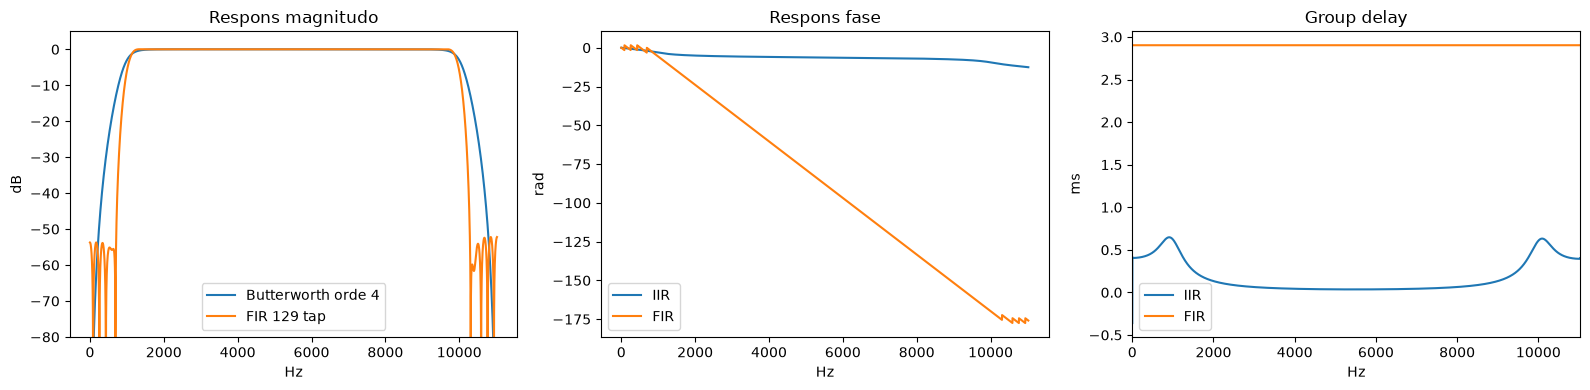

  [gambar] B1_respons_filter.png
Mode streaming: sinyal tidak disimpan di memori (satu klip diproses lalu dibuang).


In [54]:
# ====================================================================================
# SEL #39  |  B. PRAPROSES
# FUNGSI : Menjalankan B_preprocess.
# OUTPUT : GAMBAR hasil/B1_respons_filter.png (3 grafik: magnitudo, fase, group
#          delay).
# LIHAT  : Gambar tampil di bawah sel ini.
# ====================================================================================
B_preprocess(cfg, ctx)

#### Demo: pre-emphasis dan bandpass pada satu klip burung
Sel ini **tambahan khusus notebook** (tidak ada di skrip asli). Tujuannya melihat langsung efek tiap langkah pada satu klip. Gambar disimpan sebagai `B2_contoh_praproses.png`.

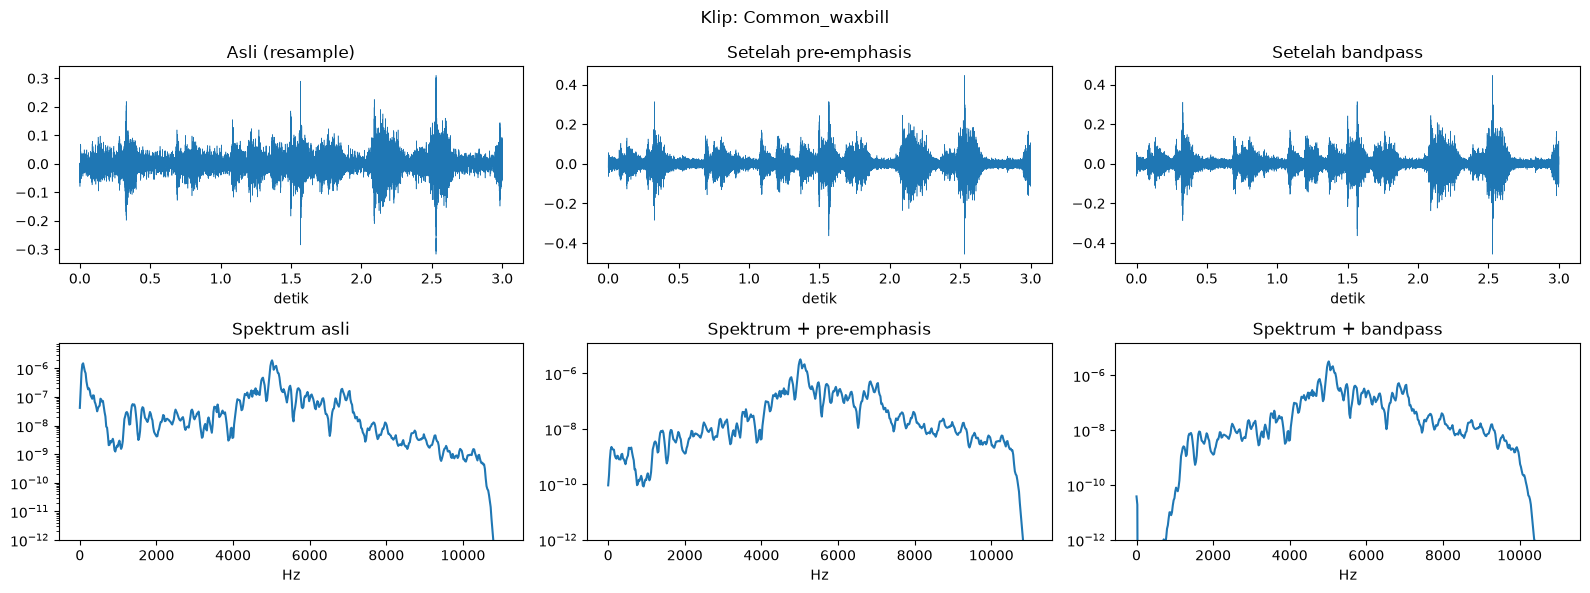

  [gambar] B2_contoh_praproses.png


In [55]:
# ====================================================================================
# SEL #41  |  B. PRAPROSES (DEMO)
# FUNGSI : Demo pada satu klip burung: bentuk gelombang dan spektrum sebelum/sesudah
#          pre-emphasis dan bandpass.
# OUTPUT : GAMBAR hasil/B2_contoh_praproses.png (2 baris x 3 kolom).
# LIHAT  : Gambar tampil di bawah sel ini. Penjelasan hasil B ada di sel markdown
#          sesudahnya.
# ====================================================================================
# Pilih satu klip burung (bukan Noise) dari data yang dipakai
i = int(np.where(ctx["df"].label.isin(ctx["bird"]))[0][0])
path = ctx["df"].path.iloc[i]
y0, _ = librosa.load(path, sr=cfg.sr, mono=True, duration=cfg.max_dur)          # setelah resample
y1 = load_preemph(path, cfg.sr, cfg.preemph, cfg.max_dur)                       # + pre-emphasis
y2 = apply_filter(y1, "iir", ctx["sos"], ctx["fir"])                            # + bandpass 1-10 kHz

fig, ax = plt.subplots(2, 3, figsize=(16, 6))
for a_, y_, t_ in zip(ax[0], (y0, y1, y2), ("Asli (resample)", "Setelah pre-emphasis", "Setelah bandpass")):
    a_.plot(np.arange(len(y_)) / cfg.sr, y_, lw=0.4); a_.set(title=t_, xlabel="detik")
for a_, y_, t_ in zip(ax[1], (y0, y1, y2), ("Spektrum asli", "Spektrum + pre-emphasis", "Spektrum + bandpass")):
    f_, P_ = signal.welch(y_, cfg.sr, nperseg=1024)
    a_.semilogy(f_, P_); a_.set(title=t_, xlabel="Hz", ylim=(1e-12, None))
fig.suptitle(f"Klip: {ctx['df'].label.iloc[i]}")
savefig(cfg, "B2_contoh_praproses.png")

### Penjelasan hasil kategori B (praproses dan kode)
**B1_respons_filter.png (sel 39).** Tiga grafik membandingkan filter bandpass 1 sampai 10 kHz:
- *Respons magnitudo:* kedua filter meloloskan 1 sampai 10 kHz dan meredam di luarnya. FIR 129 tap lebih curam di tepi pita daripada Butterworth orde 4.
- *Respons fase:* IIR berfase tidak linier, FIR berfase linier.
- *Group delay:* FIR konstan sekitar 2,9 ms di seluruh frekuensi, sedangkan IIR berubah-ubah menurut frekuensi. Karena itulah filter dijalankan **maju lalu mundur (zero-phase)** dengan `sosfiltfilt` dan `filtfilt`, supaya posisi waktu sinyal tidak bergeser.

**B2_contoh_praproses.png (sel 41).** Baris atas: bentuk gelombang satu klip burung. Baris bawah: spektrum dayanya. Pada kolom tengah (setelah pre-emphasis) bagian frekuensi rendah turun dibanding frekuensi tinggi. Pada kolom kanan (setelah bandpass) frekuensi di bawah 1 kHz dan di atas 10 kHz dipotong.

**Skrip fitur (sel 35).** `clip_features()` mengubah satu klip menjadi **52 angka**. Hasilnya tidak berupa gambar atau CSV tersendiri, tetapi disimpan sebagai matriks fitur di `fitur_*.npz` saat sel 46 dijalankan. Di run kelompok, pesan "fitur dimuat dari cache" muncul karena file itu sudah ada dari run sebelumnya.

**Hasil temuan praproses (dibahas di E, sel 66).** Bandpass menaikkan SNR burung dari 22,74 dB menjadi 23,05 dB (+0,31 dB), tetapi akurasi tidak ikut naik (lihat E2). Jadi bandpass sudah dikerjakan dan dievaluasi, hanya saja manfaat akurasinya tidak terbukti.

---
# C. Eksperimen Inti (Minggu 2)
**Butir yang diminta:** 16 konfigurasi window selesai.

- **16 konfigurasi** = 4 ukuran × 4 jenis. Definisinya ada di sel konstanta: `WIN_SIZES = [256, 512, 1024, 2048]` dan `WIN_TYPES = ["boxcar", "hann", "hamming", "blackman"]`.
- `C_core()` mengerjakan: tabel resolusi (C1), spektrogram (C2), sidelobe dan main lobe (C3), waktu ekstraksi (C4), dan **ekstraksi fitur untuk ke-16 konfigurasi** (C5, lewat `stream()`).
- Bukti selesai: `C1`–`C4` dan `fitur_*.npz`. Nanti di bagian D, ke-16 konfigurasi tampil sebagai baris di `D1_cv_hasil.csv`.

**Mendefinisikan 4 Ukuran & 4 Jenis Window (ada di cell 5)**
- Baris ini menetapkan ruang desain 4 x 4 = 16 konfigurasi:
- WIN_SIZES = [256, 512, 1024, 2048]
- WIN_TYPES = ["boxcar", "hann", "hamming", "blackman"]      # boxcar = rectangular
- NICE = {"boxcar": "Rectangular", "hann": "Hann", "hamming": "Hamming", "blackman": "Blackman"}

Menetapkan Parameter Global Eksperimen (cell 7)
Baris ini mengunci rasio hop 50% (hop_ratio=0.5), frekuensi sampling target 22.050Hz (sr=22050), pre-emphasis 0.97, dan pita bandpass 1000–10000 Hz

- def make_cfg(data_root, out_dir, full=True, merge6=False, jobs=1, sub_train=300, sub_test=100,
- sr=22050, hop_ratio=0.5, folds=5, seeds=(0, 1, 2), fir_taps=129, max_dur=3.0, seed=42):
- a.preemph, a.bp_low, a.bp_high = 0.97, 1000, 10000     # pre-emphasis 0,97; bandpass 1-10 kHz

**Membangun Ke-16 Konfigurasi + Baseline & Mengekstrak Fiturnya (Sel #44 — C_core, Bagian C5)**

Di dalam fungsi C_core(), dictionary comprehension menggabungkan setiap N di WIN_SIZES dengan setiap w di WIN_TYPES menjadi 16 kunci konfigurasi (boxcar_256 hingga blackman_2048), ditambah 1 konfigurasi baseline_hann_2048_hop512


**Menguji Desain Pembanding: Filter & Hop 75% (Sel #65 — E_analysis, Bagian E2 & E3)**

Pada bagian analisis E_analysis(), konfigurasi terbaik dari hasil validasi diuji ulang menggunakan variasi filter (none, iir, fir) dan variasi overlap 75% (hop75)

best = ctx["best"]; wb, Nb = best.split("_")[0], int(best.split("_")[1])
    # E2/E3: konfigurasi terbaik dengan variasi filter dan hop 50% vs 75%
    specs = {"best": (Nb, wb, int(Nb*cfg.hop_ratio)), "hop75": (Nb, wb, int(Nb*0.25))}
    ...
    fe, _ = stream(cfg, ctx, specs, ("none", "iir", "fir"), desc=f"E2/E3 ({best})")

**Penjelasan C2**

Grafik C2_spektrogram.png sengaja dibuat dalam format 2 baris × 4 kolom (8 panel) dengan prinsip isolasi satu variabel (one-factor-at-a-time) agar efek masing-masing parameter terlihat kontras secara visual tanpa membuat gambar terlalu padat

**Baris Atas — Khusus Menguji Efek Ukuran Window (N):**

- Jenis window dikunci pada Hann (standar umum pemrosesan sinyal audio), sedangkan ukurannya diubah-ubah: 256, 512, 1024, dan 2048
- Tujuannya: Memperlihatkan trade-off resolusi waktu dan frekuensi secara murni. Pada N=256, ketukan waktu kicauan burung terlihat tajam (Delta t = 12 ms) tetapi pita frekuensinya kabur (Delta f = 86 Hz; sebaliknya pada N=2048, garis frekuensi terlihat sangat halus (Delta f = 11\ Hz) tetapi transien waktunya melebar/buram (Delta t = 93)

**Baris Bawah — Khusus Menguji Efek Jenis Window:**
- Ukuran window dikunci pada nilai tengah kompromi N=1024, sedangkan jenis window-nya diubah-ubah: Rectangular, Hann, Hamming, dan Blackman
- Tujuannya: Memperlihatkan fenomena spectral leakage (kebocoran spektrum) pada ukuran frame yang sama. Terlihat jelas di panel kiri bawah (Rectangular N=1024) muncul garis-garis vertikal ungu yang bocor menembus area gelap di atas 10 kHz dan di bawah 1 kHz akibat sidelobe tinggi 13 dB, sedangkan pada Hann, Hamming, dan Blackman area luar pita tetap bersih hitam.

In [ ]:
# ====================================================================================
# SEL #44  |  C. EKSPERIMEN INTI
# FUNGSI : 16 KONFIGURASI WINDOW: tabel resolusi (C1), spektrogram (C2),
#          kebocoran/leakage (C3), biaya komputasi (C4), dan ekstraksi fitur 16
#          konfigurasi (C5).
# OUTPUT : Tidak ada output langsung (hanya mendefinisikan fungsi).
# LIHAT  : Dijalankan di sel 46.
# ====================================================================================
def window_metrics(name, N=1024, nfft=2**16):
    w = signal.get_window(name, N)
    mag = np.abs(np.fft.rfft(w, nfft)); db = 20*np.log10(mag/mag.max() + 1e-12)
    k = np.arange(len(db)) * N / nfft                                    # sumbu dalam bin
    mn = np.where((db[1:-1] < db[:-2]) & (db[1:-1] < db[2:]))[0][0] + 1  # null pertama
    i3 = np.argmax(db < -3)
    return ({"window": NICE[name], "Peak sidelobe (dB)": db[mn:].max(),
             "Main lobe null-ke-null (bin)": 2*k[mn], "Lebar -3 dB (bin)": 2*k[i3]}, k, db)


def C_core(cfg, ctx):
    title("C. EKSPERIMEN INTI")
    df = ctx["df"]

    # C1 trade-off resolusi (Menghitung Delta f, Delta t, dan hop untuk keempat ukuran N)
    # C1: resolusi frekuensi df = fs/N dan resolusi waktu dt = N/fs untuk tiap N
    res = pd.DataFrame([{"N": N, "df (Hz) = fs/N": cfg.sr/N, "dt (ms) = N/fs": 1000*N/cfg.sr,
                         "hop (ms)": 1000*N*cfg.hop_ratio/cfg.sr} for N in WIN_SIZES]).round(2)
    print("\nC1. Resolusi waktu-frekuensi\n" + res.to_string(index=False))
    # -> hasil/C1_tabel_resolusi.csv
    save_table(cfg, res, "C1_tabel_resolusi.csv", index=False)

    # C2 spektrogram satu klip burung (Menggambar spektrogram perbandingan untuk keempat ukuran N (baris atas) 
    # dan keempat jenis window (baris bawah))
    cand = np.where(df.label == "VillageWeaver")[0]
    i = int(cand[0]) if len(cand) else int(np.where(df.label.isin(ctx["bird"]))[0][0])
    y = load_filtered(cfg, ctx, i)
    fig, ax = plt.subplots(2, 4, figsize=(18, 7), sharey=True)
    for a, N in zip(ax[0], WIN_SIZES):
        D = librosa.amplitude_to_db(np.abs(librosa.stft(y, n_fft=N, hop_length=N//2, window="hann")), ref=np.max)
        librosa.display.specshow(D, sr=cfg.sr, hop_length=N//2, x_axis="time", y_axis="hz", ax=a, vmin=-80)
        a.set_title(f"Hann N={N} (df={cfg.sr/N:.0f} Hz, dt={1000*N/cfg.sr:.0f} ms)")
    for a, w in zip(ax[1], WIN_TYPES):
        D = librosa.amplitude_to_db(np.abs(librosa.stft(y, n_fft=1024, hop_length=512, window=w)), ref=np.max)
        librosa.display.specshow(D, sr=cfg.sr, hop_length=512, x_axis="time", y_axis="hz", ax=a, vmin=-80)
        a.set_title(f"{NICE[w]} N=1024")StopIteration
    # -> hasil/C2_spektrogram.png (atas: Hann N=256..2048; bawah: 4 jenis window pada N=1024)
    fig.suptitle(f"Klip: {df.label[i]}"); savefig(cfg, "C2_spektrogram.png")

    # C3 leakage (Mengukur peak sidelobe dan lebar main lobe keempat jenis window melalui window_metrics())
    # C3: peak sidelobe dan lebar main lobe tiap jenis window
    tab = pd.DataFrame([window_metrics(w)[0] for w in WIN_TYPES]).round(2)
    print("\nC3. Leakage tiap window (N=1024)\n" + tab.to_string(index=False))
    # -> hasil/C3_tabel_window.csv
    save_table(cfg, tab, "C3_tabel_window.csv", index=False)
    fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
    for w in WIN_TYPES:
        _, k, db = window_metrics(w); ax[0].plot(k, db, label=NICE[w])
    ax[0].set(xlim=(0, 12), ylim=(-120, 3), xlabel="Frekuensi (bin)", ylabel="dB",
              title="Respons spektral window (N=1024)"); ax[0].legend()
    N = 1024; f0 = 100.5 * cfg.sr / N; tone = np.sin(2*np.pi*f0*np.arange(N)/cfg.sr)   # di antara dua bin
    for w in WIN_TYPES:
        s_ = np.abs(np.fft.rfft(tone*signal.get_window(w, N))); s_ = 20*np.log10(s_/s_.max()+1e-12)
        ax[1].plot(np.arange(len(s_))*cfg.sr/N, s_, label=NICE[w])
    ax[1].set(xlim=(0, 6000), ylim=(-120, 3), xlabel="Hz", ylabel="dB", title=f"Leakage nada {f0:.0f} Hz"); ax[1].legend()
    # -> hasil/C3_leakage.png
    savefig(cfg, "C3_leakage.png")

    # C4 biaya komputasi (100 klip contoh, tersebar merata)
    # Mengukur waktu ekstraksi (ms_per_klip) dan ukuran matriks Mel-spectrogram untuk seluruh 16 kombinasi
    idx = np.linspace(0, len(df)-1, min(100, len(df))).astype(int)
    clips = [load_filtered(cfg, ctx, int(j)) for j in idx]; rows = []
    for N in WIN_SIZES:
        for w in WIN_TYPES:
            hop = int(N*cfg.hop_ratio); t = time.perf_counter()
            for c in clips: clip_features(c, cfg.sr, N, w, hop)
            ms = 1000*(time.perf_counter()-t)/len(clips); fr = 1 + len(clips[0])//hop
            rows.append({"window": NICE[w], "N": N, "ms_per_klip": ms, "frame": fr,
                         "ukuran_melspec(64xframe)": 64*fr, "dim_fitur_SVM": 52})
    del clips
    # C4: waktu ekstraksi per klip untuk 16 kombinasi
    cost = pd.DataFrame(rows).round(2)
    print("\nC4. Waktu ekstraksi (ms/klip)\n" + cost.pivot(index="window", columns="N", values="ms_per_klip").to_string())
    # -> hasil/C4_biaya_komputasi.csv
    save_table(cfg, cost, "C4_biaya_komputasi.csv", index=False)

    # C5 ekstraksi fitur 16 konfigurasi (+ baseline librosa) + SNR, satu kali lewat data
    # C5: 16 KONFIGURASI = 4 ukuran N x 4 jenis window (hop 50%), ditambah 1 baseline librosa
    specs = {f"{w}_{N}": (N, w, int(N*cfg.hop_ratio)) for N in WIN_SIZES for w in WIN_TYPES}
    specs["baseline_hann_2048_hop512"] = (2048, "hann", 512)
    f = cfg.out / f"fitur_{cfg.sub_train}_{cfg.sub_test}_{int(cfg.merge6)}_{cfg.max_dur:g}_utama.npz"
    # cache: jika fitur sudah pernah dihitung, dimuat dari file .npz (lebih cepat)
    if f.exists():
        z = np.load(f); feats = {k: z[k] for k in specs}; snr = z["snr"]
        print(f"  fitur dimuat dari cache: {f.name}")
    else:
        # ekstraksi 52 fitur untuk SEMUA klip dan 17 konfigurasi (lama; hanya sekali)
        fe, snr = stream(cfg, ctx, specs, ("iir",), want_snr=True, desc="ekstraksi 17 konfigurasi")
        feats = {k: fe[("iir", k)] for k in specs}
        # -> hasil/fitur_*.npz (matriks fitur + SNR)
        np.savez(f, snr=snr, **feats)
    ctx.update(feats=feats, snr=snr)

#### Jalankan bagian C


C. EKSPERIMEN INTI

C1. Resolusi waktu-frekuensi
   N  df (Hz) = fs/N  dt (ms) = N/fs  hop (ms)
 256           86.13           11.61      5.80
 512           43.07           23.22     11.61
1024           21.53           46.44     23.22
2048           10.77           92.88     46.44
  [tabel]  C1_tabel_resolusi.csv


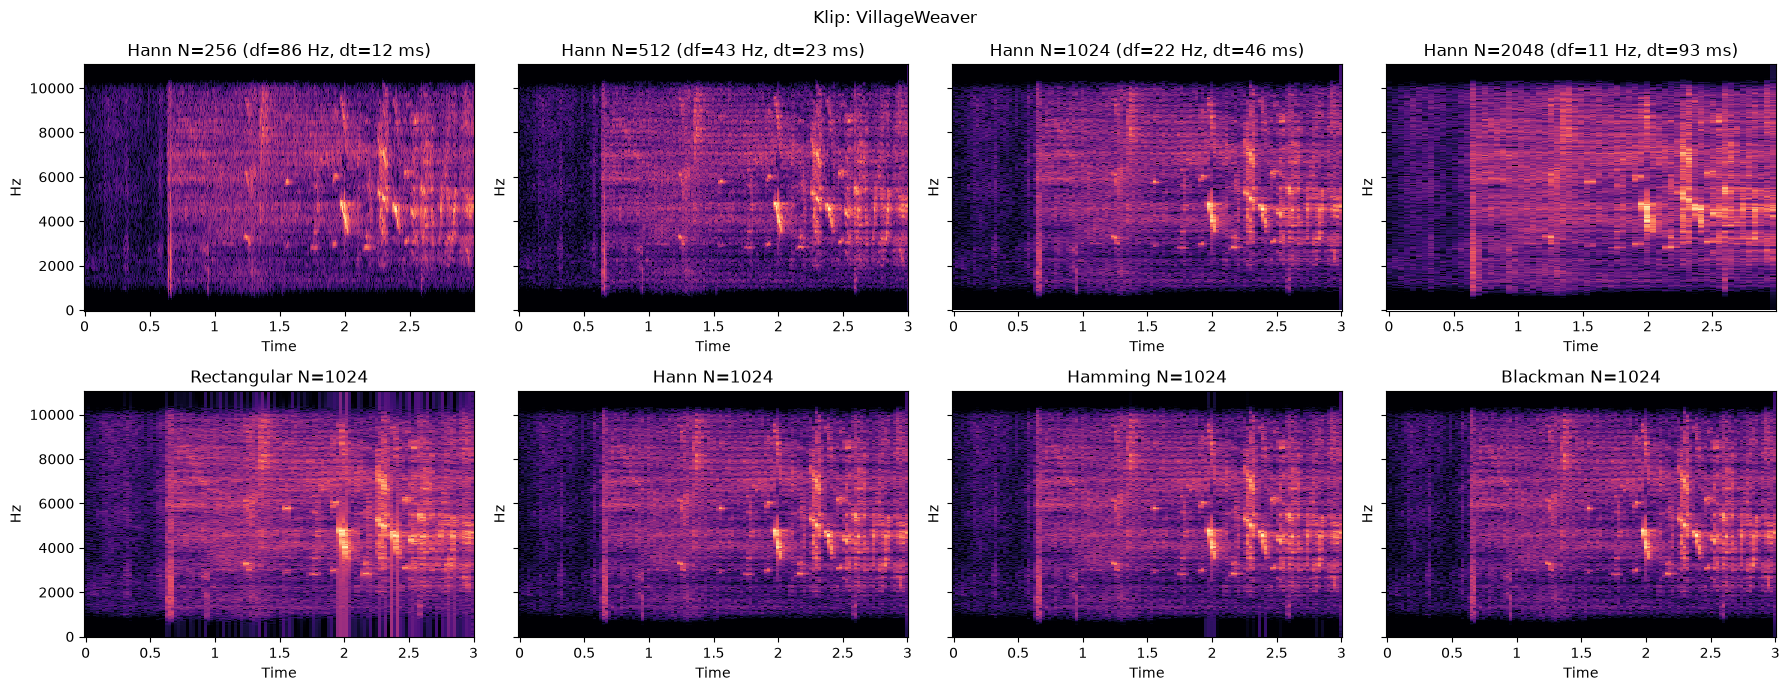

  [gambar] C2_spektrogram.png

C3. Leakage tiap window (N=1024)
     window  Peak sidelobe (dB)  Main lobe null-ke-null (bin)  Lebar -3 dB (bin)
Rectangular              -13.26                           2.0               0.91
       Hann              -31.47                           4.0               1.47
    Hamming              -42.67                           4.0               1.31
   Blackman              -58.11                           6.0               1.66
  [tabel]  C3_tabel_window.csv


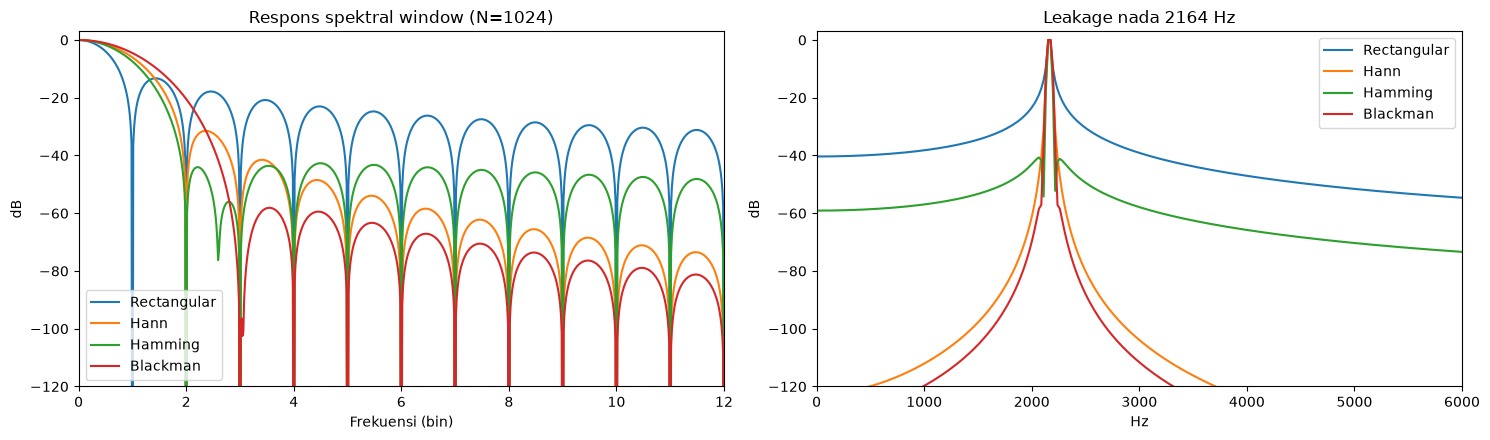

  [gambar] C3_leakage.png

C4. Waktu ekstraksi (ms/klip)
N            256   512   1024  2048
window                             
Blackman     4.08  4.14  3.46  3.23
Hamming      4.14  3.92  3.55  3.26
Hann         4.94  3.67  3.44  3.47
Rectangular  4.73  3.81  3.32  3.76
  [tabel]  C4_biaya_komputasi.csv
  fitur dimuat dari cache: fitur_None_None_0_3_utama.npz


In [57]:
# ====================================================================================
# SEL #46  |  C. EKSPERIMEN INTI
# FUNGSI : Menjalankan C_core.
# OUTPUT : Teks C1, C3, C4 di bawah sel ini. FILE: hasil/C1_tabel_resolusi.csv,
#          C2_spektrogram.png, C3_tabel_window.csv, C3_leakage.png,
#          C4_biaya_komputasi.csv, fitur_*.npz.
# LIHAT  : Tabel dan gambar tampil di bawah sel ini.
# ====================================================================================
C_core(cfg, ctx)

### Penjelasan hasil kategori C (16 konfigurasi window)
**C1, resolusi.** Memperbesar N dari 256 ke 2048 memperhalus resolusi frekuensi (df = fs/N) dari **86,13 menjadi 10,77 Hz**, tetapi memperkasar resolusi waktu (dt = N/fs) dari **11,61 menjadi 92,88 ms**. Inilah trade-off waktu lawan frekuensi.

**C2, spektrogram (`C2_spektrogram.png`).** Baris atas memperlihatkan klip yang sama dengan Hann N = 256, 512, 1024, 2048: N kecil memperlihatkan perubahan waktu halus tetapi frekuensi kabur, N besar membuat nada rapi tetapi kejadian cepat (transien) kabur. Baris bawah membandingkan 4 jenis window pada N = 1024.

**C3, kebocoran spektral.** Peak sidelobe: Rectangular **-13,26 dB**, Hann **-31,47 dB**, Hamming **-42,67 dB**, Blackman **-58,11 dB**. Lebar main lobe (null ke null): 2, 4, 4, 6 bin. Jadi sidelobe makin rendah (kebocoran makin kecil) tetapi main lobe makin lebar. Tidak ada window yang unggul di semua metrik.

**C4, biaya komputasi.** Waktu ekstraksi hanya sekitar **2,8 sampai 4,0 ms per klip** pada semua 16 kombinasi, dan selisih antar-kombinasi kecil. Angka ini bergantung pada kondisi komputer pada saat run (run sebelumnya memberi rentang sedikit berbeda), jadi jangan dipakai untuk menyatakan satu window pasti lebih cepat.

**C5, ke-16 konfigurasi selesai.** Fitur 52 dimensi sudah diekstrak untuk seluruh klip untuk ke-16 kombinasi (ditambah baseline librosa). Buktinya: `fitur_*_utama.npz`, dan di sel 51 setiap kombinasi muncul sebagai baris di `D1_cv_hasil.csv`.

---
# D. Validasi dan Uji Statistik (Minggu 2)
**Butir yang diminta:** 5-fold × 3 seed · Friedman + Nemenyi.

- **5-fold × 3 seed:** `D_validation()` memakai fold dari `make_folds()` (bagian A), yaitu `folds = ctx["folds"]`, untuk `cfg.seeds = [0, 1, 2]`. Daftar tugas `jobs` = konfigurasi × seed × fold = 16 × 3 × 5 = **240** kali latih-uji SVM (`run_fold`).
- **Uji Friedman:** `friedmanchisquare(*[M[c] for c in M.columns])`, dengan peringkat dari `M.rank(axis=1, ascending=False).mean()`.
- **Uji Nemenyi:** `sp.posthoc_nemenyi_friedman(M.values)`, disimpan ke `D2_nemenyi_p.csv` dan peta panasnya.
- Selain itu ada uji Wilcoxon (H1, H2) dan evaluasi akhir pada data testing (D3).

**Uji Tepat**

Codingan ini memastikan skema validasi tidak bocor (stratified, tanpa menyentuh data testing) dan memakai uji non-parametrik yang sesuai untuk membandingkan banyak model sekaligus pada blok validasi silang

**Sel #17 (make_folds) — Pembagian 5-Fold Berstrata × 3 Seed**

Membagi 6.799 klip training menjadi 5 fold berstrata untuk seed = 0, 1, 2 (15 blok) dan memverifikasi tidak ada klip yang tumpang tindih (assert) = **folds = {s: list(StratifiedKFold(cfg.folds, shuffle=True, random_state=s).split(idx_tr, ytr)) for s in cfg.seeds}**

**Sel #49 (D_validation) — Eksekusi 240 Fit SVM, Uji Friedman, Post-hoc Nemenyi, & Wilcoxon**

- 240 Latih-Uji SVM (16 konfigurasi x 3 seed x 5 fold) = **jobs = [(k, s, f, tr, va) for k in grid for s in cfg.seeds for f, (tr, va) in enumerate(folds[s])]
out = parallel(cfg, (delayed(run_fold)(feats[k][idx_tr], ytr, tr, va, s) for k, s, f, tr, va in jobs))**
- Uji Friedman (menguji apakah 16 konfigurasi berbeda secara keseluruhan di 15 blok) = **M = cv.pivot_table(index=["seed", "fold"], columns="key", values="macro_f1")[grid]
stat, p = friedmanchisquare(*[M[c] for c in M.columns])**
- Post-hoc Nemenyi (membandingkan seluruh (16/2) = 120 pasangan konfigurasi setelah Friedman signifikan) = **nem = sp.posthoc_nemenyi_friedman(M.values); nem.index = nem.columns = M.columns**
- Uji Wilcoxon Berpasangan (H1 & H2) (membandingkan dua kelompok konfigurasi pada blok yang sama) = **pv = wilcoxon(a, b).pvalue**
- Evaluasi Akhir Data Testing (menguji konfigurasi terbaik vs baseline librosa sekali di 1.713 klip testing) = **for key in [best, "baseline_hann_2048_hop512"]:
    clf = make_svm(cfg.seed).fit(feats[key][idx_tr], ytr); p_ = clf.predict(feats[key][idx_te])**
- Sel #65 (E_analysis) — Uji Wilcoxon Berpasangan untuk Hipotesis H3. Menguji perubahan SNR pada 6.512 klip burung sebelum vs sesudah filter bandpass = **pv = wilcoxon(b.sesudah, b.sebelum).pvalue**

**Asumsi Dicek**

Uji Friedman mensyaratkan blok pengamatan saling independen, sedangkan uji Wilcoxon mensyaratkan distribusi selisih pasangan simetris (dan dicek normalitasnya untuk melengkapi pelaporan parametrik/non-parametrik). Keduanya dicek di dua sel berikut:

**Sel #56 (sensitivitas(M))** — Cek Asumsi Independensi Blok Uji Friedman
Karena pengulangan 3 seed menggunakan data training yang sama sehingga ke-15 blok tidak sepenuhnya independen, kode ini mengulang uji Friedman pada skema blok yang benar-benar independen (per seed secara terpisah = 5 blok, dan rerata 3 seed per fold = 5 blok) lalu menyimpannya ke D4_asumsi_sensitivitas.cs
- skema = {f"semua blok ({len(M)} blok)": M}
for s in sorted(M.index.get_level_values("seed").unique()):
    skema[f"seed {s} saja"] = M.xs(s, level="seed")
skema["rerata seed per fold"] = M.groupby(level="fold").mean()

**Sel #54 (efek_berpasangan) & Sel #60** — Cek Asumsi Distribusi Selisih Uji Wilcoxon
Untuk setiap uji berpasangan (H1, H2, H3), fungsi efek_berpasangan() mengecek normalitas selisih menggunakan uji Shapiro-Wilk (shapiro(d).pvalue, untuk $n \le 5000$) dan kesimetrian distribusi selisih menggunakan skewness (skew(d))
- sh = shapiro(d).pvalue if (3 <= len(d) <= 5000 and sd > 0) else np.nan
...
shapiro_p_selisih=sh, skewness_selisih=skew(d)



**Ukuran Efek Dilaporkan**

**Sel #54 (kendall_w, nemenyi_cd) & Sel #58 — Ukuran Efek Uji Friedman & Nemenyi**
- Kendall's $W$ (ukuran kesepakatan peringkat antar-blok untuk uji Friedman; bernilai$W = 0,419 kategori sedang) = **def kendall_w(M):
    N, k = M.shape
    chi2, p = friedmanchisquare(*[M[c] for c in M.columns])
    return chi2, p, chi2 / (N * (k - 1))**

- Critical Difference (CD) Nemenyi (batas selisih peringkat minimum agar dua konfigurasi dianggap berbeda signifikan; CD = 5,96) = **def nemenyi_cd(k, N, alpha=0.05):
    q = studentized_range.ppf(1 - alpha, k, np.inf) / np.sqrt(2)
    return q * np.sqrt(k * (k + 1) / (6 * N))**

Hasil perbandingan tiap konfigurasi terhadap peringkat 1 beserta status apakah melampaui CD disimpan ke D6_nemenyi_vs_terbaik.csv dan divisualisasikan pada D4_peringkat_cd.png
- Sel #54 (efek_berpasangan), Sel #60 (H1 & H2), & Sel #69 (H3) — Ukuran Efek Uji Wilcoxon
Fungsi efek_berpasangan() menghitung tiga ukuran efek sekaligus ditambah selang kepercayaan = **r_rb = (wp - wm) / (wp + wm) if (wp + wm) > 0 else np.nan          # 1. Rank-biserial r
dz = d.mean() / sd if sd > 0 else np.nan                            # 2. Cohen's dz
boot = np.array([d[rng.integers(0, len(d), len(d))].mean() for _ in range(n_boot)])
lo, hi = np.percentile(boot, [2.5, 97.5])                           # 3. Selang kepercayaan 95% (bootstrap 5000x)**
- Sel #60 menghitung dan menyimpan ukuran efek H1 dan H2 ke D5_ukuran_efek.csv
- Sel #69 menambahkan baris ukuran efek H3 ke file D5_ukuran_efek.csv yang sama
- Sel #62 merangkum seluruh angka uji statistik, cek asumsi, dan ukuran efek tersebut menjadi kalimat siap pakai untuk laporan

In [ ]:
# ====================================================================================
# SEL #49  |  D. VALIDASI DAN UJI STATISTIK
# FUNGSI : 5-FOLD x 3 SEED (240 kali latih-uji SVM), uji FRIEDMAN, post-hoc NEMENYI,
#          uji Wilcoxon H1/H2, dan evaluasi akhir di data testing.
# OUTPUT : Tidak ada output langsung (hanya mendefinisikan fungsi).
# LIHAT  : Dijalankan di sel 51.
# ====================================================================================
def make_svm(seed):
    # SVM kernel RBF (C=10, gamma=scale, class_weight=balanced) dengan fitur distandarkan
    return make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma="scale",
                                               class_weight="balanced", random_state=seed))


def run_fold(X, y, tr, va, seed):
    # latih SVM pada fold latih, prediksi fold validasi
    clf = make_svm(seed).fit(X[tr], y[tr]); p = clf.predict(X[va])
    # macro-F1 dan akurasi satu fold
    return f1_score(y[va], p, average="macro"), accuracy_score(y[va], p)


def D_validation(cfg, ctx):
    title("D. VALIDASI & UJI STATISTIK")
    feats, y, is_tr, classes = ctx["feats"], ctx["y"], ctx["is_tr"], ctx["classes"]
    idx_tr, idx_te = np.where(is_tr)[0], np.where(~is_tr)[0]
    ytr, yte = y[idx_tr], y[idx_te]
    grid = [f"{w}_{N}" for N in WIN_SIZES for w in WIN_TYPES]
    folds = ctx["folds"]            # sudah disusun di A_data -> make_folds (pembagian sama persis)

    # DAFTAR TUGAS: 16 konfigurasi x 3 seed x 5 fold = 240
    jobs = [(k, s, f, tr, va) for k in grid for s in cfg.seeds for f, (tr, va) in enumerate(folds[s])]
    t0 = time.time()


    # jalankan 240 pelatihan + pengujian SVM
    out = parallel(cfg, (delayed(run_fold)(feats[k][idx_tr], ytr, tr, va, s) for k, s, f, tr, va in jobs))
    cv = pd.DataFrame([dict(key=k, seed=s, fold=f, macro_f1=o[0], acc=o[1]) for (k, s, f, _, _), o in zip(jobs, out)])
    cv["N"] = cv.key.str.split("_").str[1].astype(int); cv["window"] = cv.key.str.split("_").str[0]
    print(f"{len(jobs)} fit SVM selesai dalam {(time.time()-t0)/60:.1f} menit")
    # -> hasil/D1_cv_hasil.csv (240 baris)
    save_table(cfg, cv, "D1_cv_hasil.csv", index=False)
    summ = cv.groupby("key")[["macro_f1", "acc"]].agg(["mean", "std"]).round(4).sort_values(("macro_f1", "mean"), ascending=False)
    print("\nD1. Hasil CV per konfigurasi\n" + summ.to_string())

    hm = cv.groupby(["window", "N"]).macro_f1.mean().unstack().loc[WIN_TYPES]; hm.index = [NICE[w] for w in hm.index]
    plt.figure(figsize=(6.5, 3.8)); sns.heatmap(hm, annot=True, fmt=".3f", cmap="YlGnBu"); plt.title("Rerata macro-F1 (CV)")
    # -> hasil/D1_heatmap_f1.png (peta panas 4 x 4 macro-F1)
    savefig(cfg, "D1_heatmap_f1.png")

    # Friedman (blok = seed x fold) + Nemenyi
    # tabel blok (seed x fold = 15 baris) x 16 konfigurasi untuk uji statistik
    M = cv.pivot_table(index=["seed", "fold"], columns="key", values="macro_f1")[grid]


    # UJI FRIEDMAN: apakah 16 konfigurasi berbeda?
    stat, p = friedmanchisquare(*[M[c] for c in M.columns])
    print(f"\nFriedman: chi2 = {stat:.2f}, p = {p:.3g} (blok={len(M)}, konfigurasi={M.shape[1]})")
    ranks = M.rank(axis=1, ascending=False).mean().sort_values()
    print("Rerata peringkat (1 = terbaik):\n" + ranks.round(2).to_string())


    # UJI NEMENYI: bandingkan semua pasangan (120 pasangan)
    nem = sp.posthoc_nemenyi_friedman(M.values); nem.index = nem.columns = M.columns
    # -> hasil/D2_nemenyi_p.csv
    save_table(cfg, nem, "D2_nemenyi_p.csv")
    order = ranks.index.tolist()
    plt.figure(figsize=(9, 7.5))
    sns.heatmap(nem.loc[order, order], cmap="viridis_r", vmax=0.1, cbar_kws={"label": "p Nemenyi (>0,1 dipotong)"})
    # -> hasil/D2_nemenyi.png
    plt.title("Post-hoc Nemenyi (gelap = beda signifikan)"); savefig(cfg, "D2_nemenyi.png")
    best = ranks.index[0]; print("Konfigurasi terbaik (peringkat):", best)
    # -> hasil/D2_peringkat.csv
    save_table(cfg, ranks.rename("rerata_peringkat").to_frame(), "D2_peringkat.csv")


    # H1 & H2: Wilcoxon berpasangan per blok
    # H1/H2: rerata macro-F1 per blok untuk tiap kelompok
    blk = lambda keys: M[keys].mean(axis=1)
    tests = [("H1: window 512-1024 vs 256 & 2048",
              blk([f"{w}_{N}" for w in WIN_TYPES for N in (512, 1024)]), blk([f"{w}_{N}" for w in WIN_TYPES for N in (256, 2048)])),
             ("H2: Hann/Blackman vs Rectangular",
              blk([f"{w}_{N}" for w in ("hann", "blackman") for N in WIN_SIZES]), blk([f"boxcar_{N}" for N in WIN_SIZES]))]
    h_rows = []
    for nm, a, b in tests:
        try:
            # UJI WILCOXON berpasangan per blok
            pv = wilcoxon(a, b).pvalue
        except ValueError:
            pv = np.nan
        h_rows.append(dict(uji=nm, selisih_macroF1=(a-b).mean(), p_wilcoxon=pv))
        print(f"{nm}: selisih rerata macro-F1 = {(a-b).mean():+.4f}, Wilcoxon p = {pv:.3g}")
    # -> hasil/D2_H1_H2.csv
    save_table(cfg, pd.DataFrame(h_rows), "D2_H1_H2.csv", index=False)
    print("Catatan: 3 seed memakai data yang sama -> blok tidak sepenuhnya independen; p cenderung optimis.")


    # Evaluasi akhir di data testing
    summary = []
    for key in [best, "baseline_hann_2048_hop512"]:
        # EVALUASI AKHIR: latih di seluruh data training, uji di data testing
        clf = make_svm(cfg.seed).fit(feats[key][idx_tr], ytr); p_ = clf.predict(feats[key][idx_te])
        summary.append(dict(konfigurasi=key, macro_f1=f1_score(yte, p_, average="macro"), akurasi=accuracy_score(yte, p_)))
        if key == best:
            p_best = p_
    sdf = pd.DataFrame(summary).round(4)
    print("\nD3. Evaluasi akhir (data testing)\n" + sdf.to_string(index=False))
    # -> hasil/D3_test_akhir.csv
    save_table(cfg, sdf, "D3_test_akhir.csv", index=False)
    print("\n" + classification_report(yte, p_best, target_names=classes, digits=3))
    cm = confusion_matrix(yte, p_best, normalize="true")
    plt.figure(figsize=(8, 6.5)); sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=classes, yticklabels=classes)
    # -> hasil/D3_konfusi.png (matriks konfusi data testing)
    plt.xlabel("Prediksi"); plt.ylabel("Sebenarnya"); plt.title(f"Matriks konfusi (test) - {best}"); savefig(cfg, "D3_konfusi.png")
    ctx.update(best=best, folds=folds, idx_tr=idx_tr, ytr=ytr)

#### Jalankan bagian D


D. VALIDASI & UJI STATISTIK
240 fit SVM selesai dalam 2.9 menit
  [tabel]  D1_cv_hasil.csv

D1. Hasil CV per konfigurasi
              macro_f1             acc        
                  mean     std    mean     std
key                                           
boxcar_512      0.9708  0.0053  0.9729  0.0049
hamming_256     0.9708  0.0051  0.9735  0.0045
hamming_512     0.9707  0.0060  0.9731  0.0051
hann_256        0.9707  0.0062  0.9738  0.0052
blackman_256    0.9704  0.0067  0.9736  0.0056
blackman_512    0.9703  0.0058  0.9731  0.0048
boxcar_256      0.9702  0.0043  0.9730  0.0042
hann_512        0.9700  0.0061  0.9728  0.0051
hamming_1024    0.9692  0.0061  0.9721  0.0053
boxcar_1024     0.9678  0.0056  0.9707  0.0050
hann_1024       0.9668  0.0060  0.9701  0.0052
blackman_1024   0.9660  0.0067  0.9695  0.0061
blackman_2048   0.9652  0.0068  0.9686  0.0054
hann_2048       0.9650  0.0061  0.9683  0.0049
hamming_2048    0.9649  0.0069  0.9681  0.0054
boxcar_2048     0.9629  0.0062  

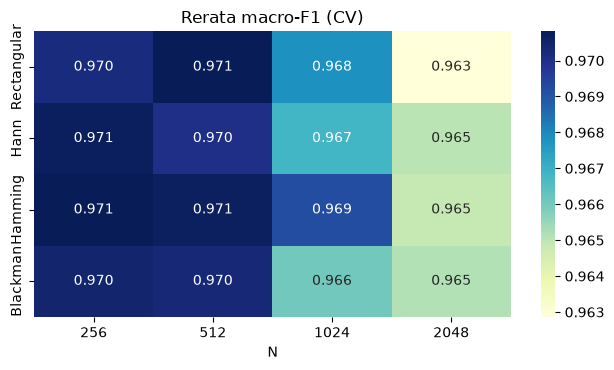

  [gambar] D1_heatmap_f1.png

Friedman: chi2 = 94.23, p = 1.6e-13 (blok=15, konfigurasi=16)
Rerata peringkat (1 = terbaik):
key
blackman_256      5.53
hann_256          5.60
hamming_256       5.60
hamming_512       5.73
blackman_512      5.87
hann_512          6.27
boxcar_512        6.40
boxcar_256        6.47
hamming_1024      7.13
boxcar_1024       8.93
hann_1024        10.13
blackman_1024    10.93
blackman_2048    12.27
hamming_2048     12.33
hann_2048        12.67
boxcar_2048      14.13
  [tabel]  D2_nemenyi_p.csv


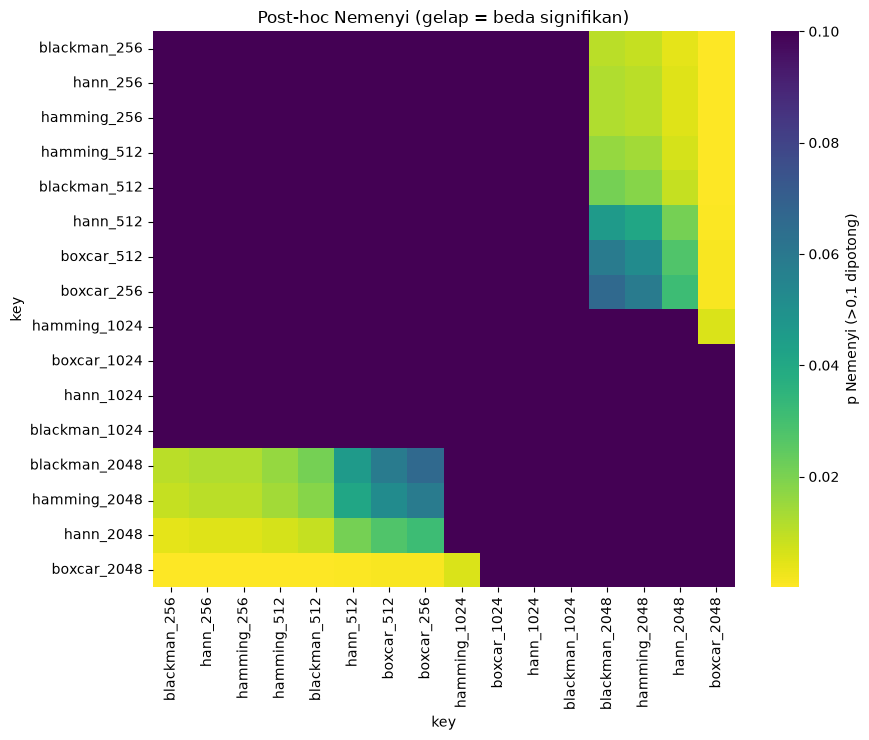

  [gambar] D2_nemenyi.png
Konfigurasi terbaik (peringkat): blackman_256
  [tabel]  D2_peringkat.csv
H1: window 512-1024 vs 256 & 2048: selisih rerata macro-F1 = +0.0015, Wilcoxon p = 0.073
H2: Hann/Blackman vs Rectangular: selisih rerata macro-F1 = +0.0002, Wilcoxon p = 0.847
  [tabel]  D2_H1_H2.csv
Catatan: 3 seed memakai data yang sama -> blok tidak sepenuhnya independen; p cenderung optimis.

D3. Evaluasi akhir (data testing)
              konfigurasi  macro_f1  akurasi
             blackman_256    0.9767   0.9796
baseline_hann_2048_hop512    0.9697   0.9720
  [tabel]  D3_test_akhir.csv

                       precision    recall  f1-score   support

       Common_waxbill      0.975     1.000     0.987       155
                Noise      0.993     0.976     0.984       409
          Other_Birds      0.981     0.996     0.988       508
      RedBilledQuelea      0.976     0.968     0.972       249
        VillageWeaver      0.976     0.976     0.976       212
Yellow-fronted Canary  

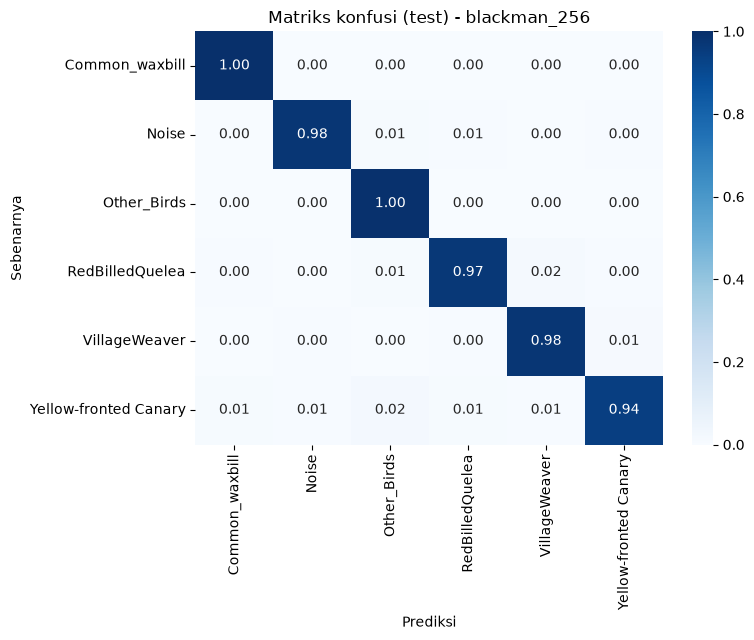

  [gambar] D3_konfusi.png


In [59]:
# ====================================================================================
# SEL #51  |  D. VALIDASI DAN UJI STATISTIK
# FUNGSI : Menjalankan D_validation.
# OUTPUT : Teks D1-D3 + gambar di bawah sel ini. FILE: hasil/D1_cv_hasil.csv,
#          D1_heatmap_f1.png, D2_nemenyi_p.csv, D2_nemenyi.png, D2_peringkat.csv,
#          D2_H1_H2.csv, D3_test_akhir.csv, D3_konfusi.png.
# LIHAT  : Tabel dan gambar tampil di bawah sel ini.
# ====================================================================================
D_validation(cfg, ctx)

### Penjelasan hasil kategori D (validasi dan uji statistik)
**5-fold x 3 seed.** Dijalankan **240 kali** latih-uji SVM (16 konfigurasi x 3 seed x 5 fold), selesai dalam sekitar 2,8 menit.

**D1, akurasi per konfigurasi.** Rerata macro-F1 berkisar dari **0,9629 (boxcar_2048)** sampai **0,9708 (boxcar_512 dan hamming_256)**. Konfigurasi N = 256 dan 512 berada di puncak (0,9700 sampai 0,9708), lalu menurun di N = 1024 dan N = 2048. Peta panas `D1_heatmap_f1.png` memperlihatkan pola ini: ukuran window mengubah hasil lebih banyak daripada jenis window.

**Uji Friedman.** chi-kuadrat = **94,23** dengan **p = 1,6 x 10^-13** (15 blok, 16 konfigurasi), jadi ke-16 konfigurasi tidak setara. Peringkat terbaik: blackman_256 (5,53); terburuk: boxcar_2048 (14,13).

**Uji Nemenyi (`D2_nemenyi.png`).** Delapan konfigurasi teratas (N = 256 dan 512) tidak dapat dibedakan satu sama lain. Semua konfigurasi N = 2048 lebih buruk secara signifikan dibanding yang terbaik.

**H1 dan H2 (Wilcoxon).** H1 (window 512-1024 lebih baik dari 256 dan 2048): selisih +0,0015, p = 0,073, **tidak signifikan**. H2 (window sidelobe rendah mengungguli rectangular): selisih +0,0002, p = 0,847, **tidak signifikan**. Jadi jenis window tidak menentukan akurasi.

**D3, uji akhir di data testing (1.713 klip).** blackman_256: macro-F1 **0,9767**, akurasi **0,9796**. Baseline librosa (Hann N = 2048, hop 512): macro-F1 0,9697, akurasi 0,9720. Selisihnya sekitar 13 klip dan belum diuji statistik. Kelas tersulit adalah Yellow-fronted Canary (F1 0,952); Noise punya recall 0,976 dan precision 0,993. Matriks konfusi ada di `D3_konfusi.png`.

---
# D.2 Pengecekan Asumsi dan Ukuran Efek (tambahan untuk kategori D)
Kriteria kategori D menyebut tiga hal: **uji tepat**, **asumsi dicek**, dan **ukuran efek dilaporkan**. Bagian D di atas sudah memenuhi butir pertama (Friedman + Nemenyi + Wilcoxon). Bagian ini melengkapi dua butir yang lain.

Sel-sel di bagian ini hanya **membaca file CSV hasil bagian D** (`D1_cv_hasil.csv`, `D2_nemenyi_p.csv`). Jadi kalau file itu sudah ada di `hasil/`, kamu cukup menjalankan sel persiapan di atas (sampai `cfg = make_cfg(...)`) lalu langsung sel-sel di bagian ini, tanpa mengulang A–D. Ukuran efek untuk **H3** (SNR bandpass) butuh hasil bagian E, jadi dihitung di bagian **E.4** setelah bagian E dijalankan.

## Apa yang diperiksa dan kenapa

| Butir kriteria | Yang dikerjakan di sini | Kenapa penting |
|---|---|---|
| **Asumsi dicek** | (1) Uji sensitivitas kemandirian blok: Friedman diulang per seed dan pada rerata seed. (2) Uji normalitas selisih berpasangan (Shapiro-Wilk). (3) Cek kesimetrian selisih (skewness). | Friedman mengandaikan blok saling independen, tetapi 3 seed memakai data yang sama. Dengan mengulang uji pada skema blok yang lebih ketat, kita melihat apakah kesimpulan bergantung pada asumsi itu. |
| **Ukuran efek dilaporkan** | (1) **Kendall's W** untuk Friedman. (2) **Rank-biserial r**, **Cohen's dz**, dan **selang kepercayaan bootstrap 95%** untuk Wilcoxon (H1 dan H2 di sini, H3 di E.4). (3) **Critical Difference (CD)** untuk Nemenyi. | p-value hanya menjawab "ada beda atau tidak". Ukuran efek menjawab "seberapa besar bedanya", dan itu krusial di proyekmu karena selisih akurasi antar-konfigurasi sangat kecil. |

## Istilah yang dipakai
- **Kendall's W** = χ² / (N × (k−1)), dengan N = jumlah blok dan k = jumlah konfigurasi. Nilainya 0–1: makin besar, makin seragam urutan konfigurasi di semua blok. Pedoman umum: < 0,1 sangat lemah, 0,1–0,3 lemah, 0,3–0,5 sedang, ≥ 0,5 kuat.
- **Rank-biserial r** (untuk Wilcoxon berpasangan) = (W⁺ − W⁻) / (W⁺ + W⁻). Rentang −1 sampai +1. Pedoman umum: |r| ≈ 0,1 kecil, 0,3 sedang, 0,5 besar.
- **Cohen's dz** = rerata selisih / simpangan baku selisih. Ukuran efek dalam satuan simpangan baku.
- **Selang kepercayaan bootstrap 95%:** blok diambil ulang dengan pengembalian 5.000 kali, lalu rerata selisih dihitung tiap kali. Kalau selang melewati 0, selisihnya tidak bisa dibedakan dari nol. Karena blok tidak sepenuhnya independen, selang ini cenderung **terlalu sempit** (optimis).
- **Critical Difference (CD) Nemenyi** = q × √(k(k+1) / (6N)). Dua konfigurasi dianggap berbeda signifikan jika selisih rerata peringkatnya lebih besar dari CD.

In [60]:
# ====================================================================================
# SEL #54  |  D. VALIDASI (D.2: ASUMSI DAN UKURAN EFEK)
# FUNGSI : Fungsi bantu: kendall_w, nemenyi_cd, efek_berpasangan (rank-biserial r,
#          Cohen's dz, CI bootstrap, Shapiro, skewness).
# OUTPUT : Tidak ada output langsung.
# LIHAT  : Dipakai oleh sel 56 sampai 69.
# ====================================================================================
from scipy.stats import shapiro, skew, studentized_range, rankdata

def fp(p):
    """Format p-value: p yang sangat kecil ditulis '< 0.001' (bukan 0)."""
    return "< 0.001" if (p == p and p < 0.001) else f"{p:.3f}"

def label_w(w):
    return "sangat lemah" if w < 0.1 else "lemah" if w < 0.3 else "sedang" if w < 0.5 else "kuat"

def label_r(r):
    a = abs(r)
    return "diabaikan" if a < 0.1 else "kecil" if a < 0.3 else "sedang" if a < 0.5 else "besar"

def kendall_w(M):
    """Uji Friedman + Kendall's W. M: baris = blok, kolom = konfigurasi."""
    N, k = M.shape
    chi2, p = friedmanchisquare(*[M[c] for c in M.columns])
    return chi2, p, chi2 / (N * (k - 1))

def nemenyi_cd(k, N, alpha=0.05):
    """Critical Difference Nemenyi pada tingkat signifikansi alpha."""
    q = studentized_range.ppf(1 - alpha, k, np.inf) / np.sqrt(2)
    return q * np.sqrt(k * (k + 1) / (6 * N))

def efek_berpasangan(a, b, n_boot=5000, seed=42):
    """Ukuran efek untuk perbandingan berpasangan a vs b (selisih = a - b)."""
    d = np.asarray(a, float) - np.asarray(b, float)
    nz = d[d != 0]
    rk = rankdata(np.abs(nz))
    wp, wm = rk[nz > 0].sum(), rk[nz < 0].sum()
    r_rb = (wp - wm) / (wp + wm) if (wp + wm) > 0 else np.nan          # rank-biserial
    sd = d.std(ddof=1)
    dz = d.mean() / sd if sd > 0 else np.nan                            # Cohen's dz
    rng = np.random.default_rng(seed)
    boot = np.array([d[rng.integers(0, len(d), len(d))].mean() for _ in range(n_boot)])
    lo, hi = np.percentile(boot, [2.5, 97.5])
    try:
        p = wilcoxon(a, b).pvalue
    except ValueError:
        p = np.nan
    sh = shapiro(d).pvalue if (3 <= len(d) <= 5000 and sd > 0) else np.nan   # Shapiro dibatasi n <= 5000
    return dict(n_pasang=len(d), selisih_rerata=d.mean(), selisih_median=np.median(d),
                ci95_bawah=lo, ci95_atas=hi, rank_biserial_r=r_rb, cohen_dz=dz,
                p_wilcoxon=p, shapiro_p_selisih=sh, skewness_selisih=skew(d))

## D.2.1 Pengecekan asumsi: sensitivitas kemandirian blok
Uji Friedman pada 15 blok (3 seed × 5 fold) mengandaikan blok saling independen. Kenyataannya, ketiga seed memakai **klip yang sama** hanya dengan pembagian fold berbeda, jadi 15 blok tidak sepenuhnya independen dan p-value cenderung optimis.

Cara mengeceknya: ulangi uji Friedman pada skema blok yang **lebih ketat**, lalu lihat apakah kesimpulannya tetap sama.
- **Per seed (5 blok):** tiap seed diuji sendiri. Blok di dalam satu seed berasal dari fold yang saling lepas.
- **Rerata 3 seed per fold (5 blok):** meredam ketergantungan antar-seed.

Kolom `rerata_peringkat_N...` menunjukkan rerata peringkat per ukuran window. Kalau N = 2048 selalu paling buruk di semua skema, kesimpulan itu kokoh terhadap asumsi independensi.

In [61]:
# ====================================================================================
# SEL #56  |  D. VALIDASI (D.2.1 ASUMSI)
# FUNGSI : Menguji sensitivitas asumsi blok independen: Friedman diulang per seed dan
#          pada rerata seed.
# OUTPUT : Tabel sensitivitas di bawah sel ini. FILE:
#          hasil/D4_asumsi_sensitivitas.csv.
# LIHAT  : Output di bawah sel ini.
# ====================================================================================
cv = pd.read_csv(cfg.out / "D1_cv_hasil.csv")
M = cv.pivot_table(index=["seed", "fold"], columns="key", values="macro_f1")
print(f"Blok = {len(M)} (seed x fold), konfigurasi = {M.shape[1]}")

def sensitivitas(M):
    skema = {f"semua blok ({len(M)} blok)": M}
    for s in sorted(M.index.get_level_values("seed").unique()):
        skema[f"seed {s} saja"] = M.xs(s, level="seed")
    skema["rerata seed per fold"] = M.groupby(level="fold").mean()
    rows = []
    for nm, Mx in skema.items():
        chi2, p, w = kendall_w(Mx)
        rk = Mx.rank(axis=1, ascending=False).mean()
        per_N = rk.groupby([int(c.split("_")[1]) for c in rk.index]).mean()
        row = dict(skema=nm, blok=len(Mx), chi2=round(chi2, 2), p_friedman=p, kendall_W=round(w, 3),
                   terbaik=rk.idxmin(), terburuk=rk.idxmax())
        row.update({f"rerata_peringkat_N{n}": round(v, 2) for n, v in per_N.items()})
        rows.append(row)
    return pd.DataFrame(rows)

sens = sensitivitas(M)
# -> hasil/D4_asumsi_sensitivitas.csv
save_table(cfg, sens, "D4_asumsi_sensitivitas.csv", index=False)
display(sens.assign(p_friedman=sens.p_friedman.map(fp)))
sig = (sens.p_friedman < 0.05).sum()
print(f"\nFriedman signifikan (p < 0.05) pada {sig} dari {len(sens)} skema blok.")
print("Skema dengan blok lebih sedikit punya daya uji lebih rendah, jadi p lebih besar adalah wajar; "
      "yang dinilai adalah apakah urutan dan arah kesimpulan (N besar lebih buruk) tetap sama.")

Blok = 15 (seed x fold), konfigurasi = 16
  [tabel]  D4_asumsi_sensitivitas.csv


,skema,blok,chi2,p_friedman,kendall_W,terbaik,terburuk,rerata_peringkat_N256,rerata_peringkat_N512,rerata_peringkat_N1024,rerata_peringkat_N2048
0,semua blok (15 blok),15,94.23,< 0.001,0.419,blackman_256,boxcar_2048,5.80,6.07,9.28,12.85
1,seed 0 saja,5,37.70,< 0.001,0.503,blackman_256,boxcar_2048,5.00,7.00,9.25,12.75
2,seed 1 saja,5,40.20,< 0.001,0.536,blackman_512,hamming_2048,6.95,4.75,8.65,13.65
3,seed 2 saja,5,28.66,0.018,0.382,boxcar_256,boxcar_2048,5.45,6.45,9.95,12.15
4,rerata seed per fold,5,55.91,< 0.001,0.745,hann_256,boxcar_2048,4.55,5.40,10.00,14.05



Friedman signifikan (p < 0.05) pada 5 dari 5 skema blok.
Skema dengan blok lebih sedikit punya daya uji lebih rendah, jadi p lebih besar adalah wajar; yang dinilai adalah apakah urutan dan arah kesimpulan (N besar lebih buruk) tetap sama.


## D.2.2 Ukuran efek: Friedman (Kendall's W) dan Nemenyi (Critical Difference)
- **Kendall's W** menunjukkan seberapa seragam urutan 16 konfigurasi di seluruh blok.
- **Critical Difference (CD)** menunjukkan seberapa jauh selisih rerata peringkat harus agar dianggap berbeda signifikan. Tabel `D6_nemenyi_vs_terbaik.csv` membandingkan **setiap konfigurasi dengan yang terbaik**: selisih peringkatnya, apakah melebihi CD, selisih rerata macro-F1, dan p Nemenyi.

Gambar `D4_peringkat_cd.png`: titik = rerata peringkat tiap konfigurasi (kiri = terbaik). Garis putus-putus berada di peringkat terbaik + CD. Konfigurasi di sebelah kanan garis itu berbeda signifikan dari yang terbaik.

Friedman: chi2 = 94.23, p = < 0.001  |  Kendall's W = 0.419 (sedang)
  [tabel]  D6_nemenyi_vs_terbaik.csv

Critical Difference (Nemenyi, alpha = 0.05, k = 16, N = 15): CD = 5.96
Konfigurasi terbaik: blackman_256



,rerata_peringkat,selisih_peringkat_vs_terbaik,melebihi_CD,rerata_macroF1,selisih_macroF1_vs_terbaik,p_nemenyi_vs_terbaik
key,,,,,,
blackman_256,5.53,0.00,False,0.9704,0.0000,1.0000
hamming_256,5.60,0.07,False,0.9708,0.0004,1.0000
hann_256,5.60,0.07,False,0.9707,0.0003,1.0000
hamming_512,5.73,0.20,False,0.9707,0.0002,1.0000
blackman_512,5.87,0.33,False,0.9703,-0.0001,1.0000
hann_512,6.27,0.73,False,0.9700,-0.0004,1.0000
boxcar_512,6.40,0.87,False,0.9708,0.0004,1.0000
boxcar_256,6.47,0.93,False,0.9702,-0.0002,1.0000
hamming_1024,7.13,1.60,False,0.9692,-0.0012,0.9999


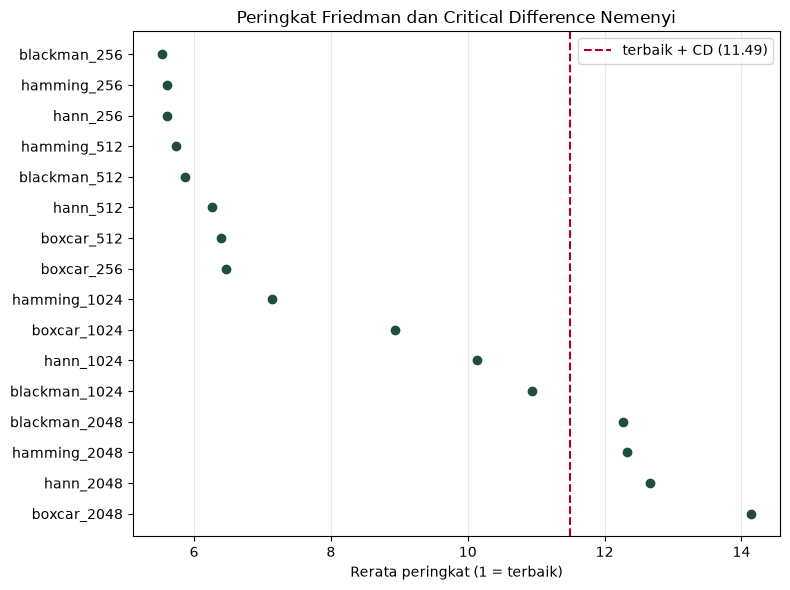

  [gambar] D4_peringkat_cd.png


In [62]:
# ====================================================================================
# SEL #58  |  D. VALIDASI (D.2.2 UKURAN EFEK)
# FUNGSI : Kendall's W untuk Friedman, Critical Difference Nemenyi, dan perbandingan
#          tiap konfigurasi dengan yang terbaik.
# OUTPUT : Tabel dan gambar. FILE: hasil/D6_nemenyi_vs_terbaik.csv,
#          hasil/D4_peringkat_cd.png.
# LIHAT  : Output di bawah sel ini.
# ====================================================================================
chi2, p, W = kendall_w(M)
print(f"Friedman: chi2 = {chi2:.2f}, p = {fp(p)}  |  Kendall's W = {W:.3f} ({label_w(W)})")

k, N = M.shape[1], len(M)
CD_ = nemenyi_cd(k, N)
ranks = M.rank(axis=1, ascending=False).mean().sort_values()
best = ranks.index[0]
nem = pd.read_csv(cfg.out / "D2_nemenyi_p.csv", index_col=0)
f1_mean = M.mean()
d6 = pd.DataFrame({
    "rerata_peringkat": ranks.round(2),
    "selisih_peringkat_vs_terbaik": (ranks - ranks[best]).round(2),
    "melebihi_CD": (ranks - ranks[best]) > CD_,
    "rerata_macroF1": f1_mean[ranks.index].round(4),
    "selisih_macroF1_vs_terbaik": (f1_mean[ranks.index] - f1_mean[best]).round(4),
    "p_nemenyi_vs_terbaik": nem.loc[ranks.index, best].round(4)})
# -> hasil/D6_nemenyi_vs_terbaik.csv
save_table(cfg, d6, "D6_nemenyi_vs_terbaik.csv")
print(f"\nCritical Difference (Nemenyi, alpha = 0.05, k = {k}, N = {N}): CD = {CD_:.2f}")
print(f"Konfigurasi terbaik: {best}\n")
display(d6)

plt.figure(figsize=(8, 6))
yy = np.arange(len(ranks))[::-1]
plt.scatter(ranks.values, yy, color="#1F4E3D", zorder=3)
plt.axvline(ranks[best] + CD_, ls="--", color="#B00020", label=f"terbaik + CD ({ranks[best] + CD_:.2f})")
plt.yticks(yy, ranks.index); plt.xlabel("Rerata peringkat (1 = terbaik)")
plt.title("Peringkat Friedman dan Critical Difference Nemenyi"); plt.legend(); plt.grid(axis="x", alpha=0.3)
# -> hasil/D4_peringkat_cd.png
savefig(cfg, "D4_peringkat_cd.png")

## D.2.3 Ukuran efek dan asumsi untuk uji Wilcoxon (H1, H2)
Untuk setiap hipotesis dihitung: selisih rerata dan median, selang kepercayaan bootstrap 95%, rank-biserial r, Cohen's dz, dan p Wilcoxon. Dua kolom tambahan dipakai untuk **mengecek asumsi**:
- `shapiro_p_selisih`: uji normalitas selisih. Jika p < 0,05, selisih tidak normal, dan itu **membenarkan pemakaian uji non-parametrik** (Wilcoxon) dan bukan uji-t berpasangan. Jika p ≥ 0,05, uji-t sebenarnya juga boleh, tetapi Wilcoxon tetap sah.
- `skewness_selisih`: kemiringan distribusi selisih. Wilcoxon mengandaikan distribusi selisih kira-kira simetris. Nilai mendekati 0 berarti simetris; |skewness| > 1 menandakan kemiringan kuat.

Definisi H1 dan H2 sama persis dengan di bagian D. Uji H3 (bandpass dan SNR) memakai data per klip dari bagian E, jadi ukuran efeknya ditambahkan di **E.4**, ke file `D5_ukuran_efek.csv` yang sama.

In [63]:
# ====================================================================================
# SEL #60  |  D. VALIDASI (D.2.3 UKURAN EFEK WILCOXON)
# FUNGSI : Ukuran efek dan cek asumsi (Shapiro, skewness) untuk H1 dan H2.
# OUTPUT : Tabel di bawah sel ini. FILE: hasil/D5_ukuran_efek.csv (H3 ditambahkan di
#          sel 69).
# LIHAT  : Output di bawah sel ini.
# ====================================================================================
blk = lambda keys: M[keys].mean(axis=1)
pasangan = [
    ("H1: window 512-1024 vs 256 & 2048",
     blk([f"{w}_{n}" for w in WIN_TYPES for n in (512, 1024)]), blk([f"{w}_{n}" for w in WIN_TYPES for n in (256, 2048)])),
    ("H2: Hann/Blackman vs Rectangular",
     blk([f"{w}_{n}" for w in ("hann", "blackman") for n in WIN_SIZES]), blk([f"boxcar_{n}" for n in WIN_SIZES]))]

rows = []
for nm, a, b in pasangan:
    rows.append(dict(uji=nm, satuan="macro-F1", **efek_berpasangan(a.values, b.values)))


d5 = pd.DataFrame(rows)
# -> hasil/D5_ukuran_efek.csv (H1 dan H2)
save_table(cfg, d5, "D5_ukuran_efek.csv", index=False)
tampil = d5.copy()
tampil["p_wilcoxon"] = tampil.p_wilcoxon.map(fp)
tampil["interpretasi_r"] = tampil.rank_biserial_r.map(label_r)
tampil["selang_melewati_0"] = (tampil.ci95_bawah <= 0) & (tampil.ci95_atas >= 0)
display(tampil.round(4))

  [tabel]  D5_ukuran_efek.csv


,uji,satuan,n_pasang,selisih_rerata,selisih_median,ci95_bawah,ci95_atas,rank_biserial_r,cohen_dz,p_wilcoxon,shapiro_p_selisih,skewness_selisih,interpretasi_r,selang_melewati_0
0,H1: window 512-1024 vs 256 & 2048,macro-F1,15,0.0015,0.0013,0.0001,0.0028,0.5333,0.5248,0.073,0.8253,0.3810,besar,False
1,H2: Hann/Blackman vs Rectangular,macro-F1,15,0.0002,0.0001,-0.0016,0.0019,0.0667,0.0422,0.847,0.7985,-0.2324,diabaikan,True


## D.2.4 Ringkasan otomatis dan cara menulisnya di laporan
Sel berikut menyusun kalimat ringkas (untuk H1 dan H2) dari angka yang sudah dihitung, supaya angka di laporan **sama persis** dengan yang ada di file CSV. Kamu tinggal menyesuaikan gaya bahasanya.

Beberapa hal yang perlu tetap kamu sebut di bagian keterbatasan:
1. 15 blok berasal dari data yang sama, jadi p-value cenderung optimis (hasil uji sensitivitas D.2.1 menunjukkan seberapa jauh kesimpulan bergantung pada hal ini).
2. Selang kepercayaan bootstrap memperlakukan blok sebagai independen, sehingga cenderung terlalu sempit.
3. Pedoman interpretasi (W, r, dz) adalah aturan praktis, bukan batas mutlak.

In [64]:
# ====================================================================================
# SEL #62  |  D. VALIDASI (D.2.4 RINGKASAN)
# FUNGSI : Menyusun kalimat ringkasan otomatis untuk laporan dari angka yang sudah
#          dihitung.
# OUTPUT : Teks ringkasan di bawah sel ini. Tidak ada file baru.
# LIHAT  : Output di bawah sel ini.
# ====================================================================================
print("RINGKASAN UNTUK LAPORAN\n" + "=" * 60)
print(f"- Uji Friedman pada {N} blok dan {k} konfigurasi: chi2 = {chi2:.2f}, p {fp(p)}; "
      f"Kendall's W = {W:.2f} ({label_w(W)}); "
      + ("urutan konfigurasi cukup konsisten antar-blok." if W >= 0.3 else "urutan konfigurasi belum terlalu konsisten antar-blok."))
print(f"- Nemenyi: CD = {CD_:.2f}. Konfigurasi terbaik {best}; "
      f"{int((~d6.melebihi_CD).sum()) - 1} konfigurasi lain tidak berbeda signifikan darinya, "
      f"{int(d6.melebihi_CD.sum())} berbeda signifikan.")
for _, r_ in d5.iterrows():
    kalimat = (f"- {r_.uji}: selisih rerata {r_.selisih_rerata:+.4f} {r_.satuan} "
               f"(CI95% {r_.ci95_bawah:+.4f} s.d. {r_.ci95_atas:+.4f}), r = {r_.rank_biserial_r:+.2f} "
               f"({label_r(r_.rank_biserial_r)}), dz = {r_.cohen_dz:+.2f}, p = {fp(r_.p_wilcoxon)}")
    if r_.shapiro_p_selisih == r_.shapiro_p_selisih:
        kalimat += f"; Shapiro p = {fp(r_.shapiro_p_selisih)}"
    print(kalimat + f"; skewness = {r_.skewness_selisih:+.2f}.")
print("\nFile bukti: D4_asumsi_sensitivitas.csv, D5_ukuran_efek.csv, D6_nemenyi_vs_terbaik.csv, D4_peringkat_cd.png")
print("(Ukuran efek H3 ditambahkan di bagian E.4 setelah bagian E dijalankan.)")

RINGKASAN UNTUK LAPORAN
- Uji Friedman pada 15 blok dan 16 konfigurasi: chi2 = 94.23, p < 0.001; Kendall's W = 0.42 (sedang); urutan konfigurasi cukup konsisten antar-blok.
- Nemenyi: CD = 5.96. Konfigurasi terbaik blackman_256; 11 konfigurasi lain tidak berbeda signifikan darinya, 4 berbeda signifikan.
- H1: window 512-1024 vs 256 & 2048: selisih rerata +0.0015 macro-F1 (CI95% +0.0001 s.d. +0.0028), r = +0.53 (besar), dz = +0.52, p = 0.073; Shapiro p = 0.825; skewness = +0.38.
- H2: Hann/Blackman vs Rectangular: selisih rerata +0.0002 macro-F1 (CI95% -0.0016 s.d. +0.0019), r = +0.07 (diabaikan), dz = +0.04, p = 0.847; Shapiro p = 0.798; skewness = -0.23.

File bukti: D4_asumsi_sensitivitas.csv, D5_ukuran_efek.csv, D6_nemenyi_vs_terbaik.csv, D4_peringkat_cd.png
(Ukuran efek H3 ditambahkan di bagian E.4 setelah bagian E dijalankan.)


### Penjelasan hasil D.2 (asumsi dan ukuran efek)
*Angka dari run kelompok.*

**Asumsi (sel 56).** Friedman tetap signifikan pada **5 dari 5 skema blok** (semua 15 blok, tiap seed sendiri, dan rerata seed per fold). Konfigurasi N = 2048 selalu berada di peringkat terburuk pada semua skema, jadi kesimpulan "N = 2048 lebih buruk" tidak bergantung pada asumsi blok independen. Namun konfigurasi terbaik tunggal berganti-ganti antar-skema (blackman_256, blackman_512, boxcar_256, hann_256), yang konsisten dengan temuan bahwa konfigurasi N = 256 dan 512 setara.

**Ukuran efek Friedman (sel 58).** Kendall's W = **0,419 (sedang)**: urutan konfigurasi cukup konsisten antar-blok. Critical Difference Nemenyi = **5,96**; 11 konfigurasi tidak berbeda signifikan dari blackman_256 dan 4 berbeda (keempatnya N = 2048).

**Ukuran efek Wilcoxon (sel 60).** H1: selisih +0,0015 (CI95% +0,0001 sampai +0,0028), r = +0,53, dz = +0,52, p = 0,073. H2: selisih +0,0002 (CI95% -0,0016 sampai +0,0019), r = +0,07, p = 0,847. Uji Shapiro (p = 0,825 dan 0,798) dan skewness (+0,38 dan -0,23) menunjukkan selisih cukup normal dan simetris, jadi asumsi Wilcoxon terpenuhi untuk H1 dan H2. **Catatan penting H1:** ukuran efeknya tampak sedang-besar dan CI bootstrap hampir tidak melewati nol, tetapi p Wilcoxon 0,073 tidak signifikan dan selisih mutlaknya hanya 0,0015 macro-F1. Karena blok tidak sepenuhnya independen (3 seed memakai data yang sama), CI cenderung terlalu sempit, jadi H1 tetap dinyatakan tidak terdukung secara statistik, dengan catatan arahnya positif.

---
# E. Analisis dan F. Reproduksibilitas (tambahan)
Dua bagian ini ada di skrip asli: E mengukur efek bandpass pada SNR dan akurasi serta ablasi hop (`E1`–`E3`), dan F menyimpan semua parameter dan versi library ke `F_konfigurasi_eksperimen.json`.

In [65]:
# ====================================================================================
# SEL #65  |  E/F. ANALISIS DAN REPRODUKSIBILITAS
# FUNGSI : E1: SNR sebelum/sesudah bandpass (H3). E2: dengan/tanpa filter. E3: hop 50%
#          vs 75%. F: simpan semua parameter dan versi library.
# OUTPUT : Tidak ada output langsung (hanya mendefinisikan fungsi).
# LIHAT  : Dijalankan di sel 66.
# ====================================================================================
def E_analysis(cfg, ctx):
    title("E. ANALISIS & PEMBAHASAN")
    lab = ctx["df"].label.values

    # E1: H3, SNR sebelum/sesudah bandpass (dihitung saat ekstraksi fitur)
    # E1: SNR sebelum/sesudah bandpass untuk tiap klip
    snr = pd.DataFrame({"label": lab, "sebelum": ctx["snr"][:, 0], "sesudah": ctx["snr"][:, 1]})
    snr["kelompok"] = np.where(snr.label == "Noise", "Noise", "Burung")
    b = snr[snr.kelompok == "Burung"]
    # uji Wilcoxon berpasangan untuk H3
    pv = wilcoxon(b.sesudah, b.sebelum).pvalue
    print(f"E1. Burung: SNR {b.sebelum.mean():.2f} dB -> {b.sesudah.mean():.2f} dB "
          f"(selisih {(b.sesudah-b.sebelum).mean():+.2f} dB), Wilcoxon p = {pv:.2e}, n = {len(b)}")
    yb = (snr.kelompok == "Burung").astype(int)
    print(f"    AUC burung-vs-noise dari SNR: {roc_auc_score(yb, snr.sebelum):.3f} -> {roc_auc_score(yb, snr.sesudah):.3f}"
          " (indikator kasar)")
    print(snr.groupby("label")[["sebelum", "sesudah"]].mean().round(2).to_string())
    # -> hasil/E1_snr.csv
    save_table(cfg, snr, "E1_snr.csv", index=False)
    m = snr.melt(id_vars="kelompok", value_vars=["sebelum", "sesudah"], var_name="filter", value_name="SNR (dB)")
    plt.figure(figsize=(6, 4)); sns.boxplot(data=m, x="kelompok", y="SNR (dB)", hue="filter")
    # -> hasil/E1_snr.png
    plt.title("SNR sebelum vs sesudah bandpass"); savefig(cfg, "E1_snr.png")

    # E2 (tanpa filter / FIR) & E3 (hop 75%) untuk konfigurasi terbaik: satu lewat data tambahan
    best = ctx["best"]; wb, Nb = best.split("_")[0], int(best.split("_")[1])
    # E2/E3: konfigurasi terbaik dengan variasi filter dan hop 50% vs 75%
    specs = {"best": (Nb, wb, int(Nb*cfg.hop_ratio)), "hop75": (Nb, wb, int(Nb*0.25))}
    f = cfg.out / f"fitur_{cfg.sub_train}_{cfg.sub_test}_{int(cfg.merge6)}_{cfg.max_dur:g}_E_{best}.npz"
    if f.exists():
        z = np.load(f); ex = {k: z[k] for k in z.files}
    else:
        fe, _ = stream(cfg, ctx, specs, ("none", "iir", "fir"), desc=f"E2/E3 ({best})")
        ex = {f"{k[0]}|{k[1]}": v for k, v in fe.items()}; np.savez(f, **ex)

    def cv_score(X):
        sc = [run_fold(X[ctx["idx_tr"]], ctx["ytr"], tr, va, 0)[0] for tr, va in ctx["folds"][cfg.seeds[0]]]
        return np.mean(sc), np.std(sc)
    # E2: CV tanpa filter vs IIR vs FIR
    rows = [dict(filter=k, macro_f1=cv_score(ex[f"{k}|best"])[0], std=cv_score(ex[f"{k}|best"])[1]) for k in ("none", "iir", "fir")]
    f2 = pd.DataFrame(rows).round(4)
    print(f"\nE2. Pengaruh filter ({best}, CV seed {cfg.seeds[0]})\n" + f2.to_string(index=False))
    # -> hasil/E2_filter_vs_akurasi.csv
    save_table(cfg, f2, "E2_filter_vs_akurasi.csv", index=False)

    rows = []
    for name, key in (("50%", "iir|best"), ("75%", "iir|hop75")):
        mu, sd = cv_score(ex[key]); rows.append({"overlap": name, "macro_f1": mu, "std": sd})
    f3 = pd.DataFrame(rows).round(4)
    print("\nE3. Ablasi overlap/hop\n" + f3.to_string(index=False))
    # -> hasil/E3_ablasi_hop.csv
    save_table(cfg, f3, "E3_ablasi_hop.csv", index=False)


def F_report(cfg, ctx):
    title("F. REPRODUKSIBILITAS")
    env = dict(python=platform.python_version(), numpy=np.__version__, scipy=scipy.__version__,
               librosa=librosa.__version__, sklearn=sklearn.__version__, target_sr=cfg.sr, preemph=cfg.preemph,
               bandpass=[cfg.bp_low, cfg.bp_high], max_dur=cfg.max_dur, jobs=cfg.jobs, fir_taps=cfg.fir_taps, win_sizes=WIN_SIZES, win_types=WIN_TYPES,
               hop_ratio=cfg.hop_ratio, folds=cfg.folds, seeds=cfg.seeds, global_seed=cfg.seed,
               sub_train=cfg.sub_train, sub_test=cfg.sub_test, merge6=cfg.merge6, classes=ctx["classes"],
               n_train=int(ctx["is_tr"].sum()), n_test=int((~ctx["is_tr"]).sum()), best_config=ctx["best"],
               svm=dict(kernel="rbf", C=10, gamma="scale", class_weight="balanced"))
    # -> hasil/F_konfigurasi_eksperimen.json (semua parameter + versi library)
    (cfg.out / "F_konfigurasi_eksperimen.json").write_text(json.dumps(env, indent=2, ensure_ascii=False), encoding="utf-8")
    print(json.dumps(env, indent=2, ensure_ascii=False))
    print(f"\nSemua luaran ada di: {cfg.out}")
    print("Keterbatasan untuk laporan: spesies Afrika Timur; label dari BirdNET (mungkin salah label); klip dari "
          "rekaman yang sama bisa muncul di fold training & validasi (CV cenderung optimis, karena itu ada test "
          "terpisah); kelas Noise bergaya ESC-50, belum tentu persis noise sawah.")


E. ANALISIS & PEMBAHASAN
E1. Burung: SNR 22.74 dB -> 23.05 dB (selisih +0.31 dB), Wilcoxon p = 0.00e+00, n = 6512
    AUC burung-vs-noise dari SNR: 0.506 -> 0.503 (indikator kasar)
                         sebelum    sesudah
label                                      
Common_waxbill         23.330000  23.709999
Noise                  23.540001  23.889999
Other_Birds            20.180000  20.590000
RedBilledQuelea        22.750000  22.950001
VillageWeaver          22.530001  22.730000
Yellow-fronted Canary  29.510000  29.770000
  [tabel]  E1_snr.csv


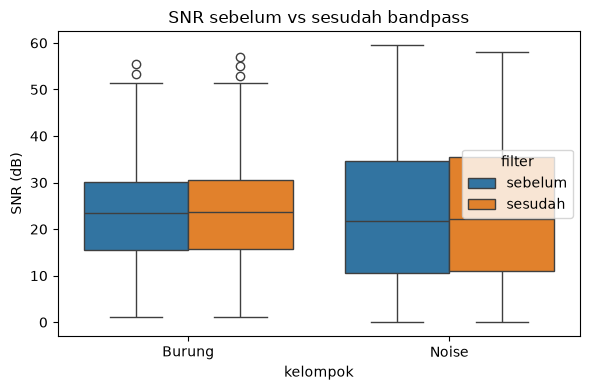

  [gambar] E1_snr.png

E2. Pengaruh filter (blackman_256, CV seed 0)
filter  macro_f1    std
  none    0.9740 0.0078
   iir    0.9711 0.0085
   fir    0.9716 0.0075
  [tabel]  E2_filter_vs_akurasi.csv

E3. Ablasi overlap/hop
overlap  macro_f1    std
    50%    0.9711 0.0085
    75%    0.9701 0.0055
  [tabel]  E3_ablasi_hop.csv

F. REPRODUKSIBILITAS
{
  "python": "3.12.3",
  "numpy": "2.5.4",
  "scipy": "1.18.1",
  "librosa": "1.0.1",
  "sklearn": "1.9.1",
  "target_sr": 22050,
  "preemph": 0.97,
  "bandpass": [
    1000,
    10000
  ],
  "max_dur": 3.0,
  "jobs": 1,
  "fir_taps": 129,
  "win_sizes": [
    256,
    512,
    1024,
    2048
  ],
  "win_types": [
    "boxcar",
    "hann",
    "hamming",
    "blackman"
  ],
  "hop_ratio": 0.5,
  "folds": 5,
  "seeds": [
    0,
    1,
    2
  ],
  "global_seed": 42,
  "sub_train": null,
  "sub_test": null,
  "merge6": false,
  "classes": [
    "Common_waxbill",
    "Noise",
    "Other_Birds",
    "RedBilledQuelea",
    "VillageWeaver",
    "

In [66]:
# ====================================================================================
# SEL #66  |  E/F. ANALISIS DAN REPRODUKSIBILITAS
# FUNGSI : Menjalankan E_analysis dan F_report.
# OUTPUT : Teks E1-E3 dan JSON F di bawah sel ini. FILE: hasil/E1_snr.csv, E1_snr.png,
#          E2_filter_vs_akurasi.csv, E3_ablasi_hop.csv, F_konfigurasi_eksperimen.json.
# LIHAT  : Teks dan gambar tampil di bawah sel ini.
# ====================================================================================
t0 = time.time()
E_analysis(cfg, ctx)
F_report(cfg, ctx)
print(f"\nSELESAI (bagian E-F) dalam {(time.time()-t0)/60:.1f} menit")

### Penjelasan hasil E dan F
**E1, SNR (H3).** SNR klip burung naik dari **22,74 dB menjadi 23,05 dB** (+0,31 dB, n = 6.512 klip). Namun AUC burung-vs-noise dari SNR hampir tidak berubah (0,506 menjadi 0,503), artinya SNR bukan pembeda burung dan noise yang berguna.

**E2, pengaruh filter** (blackman_256, CV seed 0): tanpa filter macro-F1 **0,9740**, IIR 0,9711, FIR 0,9716. Jadi filter justru tidak meningkatkan akurasi. Karena itu rekomendasi sistem adalah tanpa bandpass.

**E3, overlap:** hop 50% memberi 0,9711 dan hop 75% memberi 0,9701, jadi overlap 75% tidak menambah akurasi dan hanya menambah jumlah frame.

**F, reproduksibilitas.** `F_konfigurasi_eksperimen.json` mencatat semua parameter (fs 22.050, pre-emphasis 0,97, bandpass 1000-10000 Hz, 129 tap FIR, hop 50%, 5 fold, seed 0/1/2, SVM RBF C = 10) dan versi library (Python 3.12.3, librosa 1.0.1, scikit-learn 1.9.1).

## E.4 Ukuran efek untuk H3 (bandpass menaikkan SNR burung)
Bagian ini adalah lanjutan **D.2.3**: ukuran efek untuk H3 dihitung di sini karena datanya (`E1_snr.csv`) baru tersedia setelah bagian E dijalankan. Syaratnya, sel D.2 di atas (yang mendefinisikan `efek_berpasangan`) sudah dijalankan.

Ukuran sampel H3 besar (sekitar 6.500 klip burung), sehingga **p-value akan sangat kecil walau selisihnya hanya sekitar 0,3 dB**. Itulah gunanya ukuran efek: rank-biserial r dan Cohen's dz menunjukkan apakah selisih itu bermakna secara praktis. Hasilnya ditambahkan sebagai baris baru di `D5_ukuran_efek.csv`. Uji normalitas Shapiro dikosongkan karena hanya valid untuk n <= 5.000.

In [67]:
# ====================================================================================
# SEL #69  |  E.4 UKURAN EFEK H3
# FUNGSI : Ukuran efek untuk H3 (SNR sebelum vs sesudah bandpass), ditambahkan sebagai
#          baris baru ke D5_ukuran_efek.csv.
# OUTPUT : Tabel + satu kalimat ringkasan. FILE: hasil/D5_ukuran_efek.csv
#          (diperbarui).
# LIHAT  : Output di bawah sel ini.
# ====================================================================================
f_snr, f_d5 = cfg.out / "E1_snr.csv", cfg.out / "D5_ukuran_efek.csv"
assert f_snr.exists(), "E1_snr.csv belum ada: jalankan bagian E dulu."
assert f_d5.exists(), "D5_ukuran_efek.csv belum ada: jalankan sel D.2.3 dulu."

snr = pd.read_csv(f_snr)
snr = snr[snr.kelompok == "Burung"]
h3 = dict(uji="H3: SNR burung sesudah vs sebelum bandpass", satuan="dB",
          **efek_berpasangan(snr.sesudah.values, snr.sebelum.values))

d5 = pd.read_csv(f_d5)
d5 = d5[~d5.uji.str.startswith("H3")]                       # hindari baris ganda jika sel dijalankan ulang
d5 = pd.concat([d5, pd.DataFrame([h3])], ignore_index=True)
save_table(cfg, d5, "D5_ukuran_efek.csv", index=False)

tampil = d5.copy()
tampil["p_wilcoxon"] = tampil.p_wilcoxon.map(fp)
tampil["interpretasi_r"] = tampil.rank_biserial_r.map(label_r)
tampil["selang_melewati_0"] = (tampil.ci95_bawah <= 0) & (tampil.ci95_atas >= 0)
display(tampil.round(4))

print(f"\n- {h3['uji']}: selisih rerata {h3['selisih_rerata']:+.4f} dB "
      f"(CI95% {h3['ci95_bawah']:+.4f} s.d. {h3['ci95_atas']:+.4f}), r = {h3['rank_biserial_r']:+.2f} "
      f"({label_r(h3['rank_biserial_r'])}), dz = {h3['cohen_dz']:+.2f}, p = {fp(h3['p_wilcoxon'])}, "
      f"n = {h3['n_pasang']} klip; skewness = {h3['skewness_selisih']:+.2f}.")

  [tabel]  D5_ukuran_efek.csv


,uji,satuan,n_pasang,selisih_rerata,selisih_median,ci95_bawah,ci95_atas,rank_biserial_r,cohen_dz,p_wilcoxon,shapiro_p_selisih,skewness_selisih,interpretasi_r,selang_melewati_0
0,H1: window 512-1024 vs 256 & 2048,macro-F1,15,0.0015,0.0013,0.0001,0.0028,0.5333,0.5248,0.073,0.8253,0.3810,besar,False
1,H2: Hann/Blackman vs Rectangular,macro-F1,15,0.0002,0.0001,-0.0016,0.0019,0.0667,0.0422,0.847,0.7985,-0.2324,diabaikan,True
2,H3: SNR burung sesudah vs sebelum bandpass,dB,6512,0.3102,0.2026,0.2978,0.3231,0.9727,0.6051,< 0.001,NaN,8.8550,besar,False



- H3: SNR burung sesudah vs sebelum bandpass: selisih rerata +0.3102 dB (CI95% +0.2978 s.d. +0.3231), r = +0.97 (besar), dz = +0.61, p = < 0.001, n = 6512 klip; skewness = +8.86.


### Penjelasan hasil H3 (ukuran efek)
Selisih SNR rerata **+0,31 dB** (CI95% +0,2978 sampai +0,3231), r = **+0,97**, Cohen's dz = **+0,61**, p < 0,001, n = 6.512 klip. Hampir semua klip mengalami kenaikan SNR (r mendekati 1), dan ukuran efek terstandarnya sedang (dz = 0,61).

**Peringatan asumsi:** skewness selisih = **+8,86**, jauh dari simetris, sehingga asumsi simetri uji Wilcoxon **dilanggar kuat** untuk H3 dan Shapiro tidak dihitung (n lebih dari 5.000). Arah efeknya tetap jelas, tetapi p-value dan ukuran efek H3 sebaiknya dilaporkan dengan catatan ini (uji tanda adalah alternatif yang lebih sesuai untuk selisih miring).

**Makna praktis:** bandpass benar-benar menaikkan SNR secara statistik, tetapi kenaikan 0,31 dB itu kecil dan tidak diterjemahkan menjadi akurasi lebih tinggi (E2). Jadi H3 hanya terdukung secara statistik, bukan secara praktis.

---
# Ringkasan: bukti untuk 4 kategori
| Kategori | Butir | Kode (sel) | Output / bukti | Penjelasan hasil |
|---|---|---|---|---|
| **A. Kesiapan data** | Data terunduh, fs, jumlah klip per kelas | `scan_wavs` (13), `A_data` (19); dijalankan 21 | A1, A1b, A2, A2b (sel 23, 24) | setelah sel 25 |
| | 5 fold tersusun | `make_folds` (17) | A4, A5 (sel 25) | setelah sel 25 |
| **B. Praproses dan kode** | Pre-emphasis | `load_preemph` (31) | B2 (sel 41) | setelah sel 41 |
| | Bandpass | `make_filters` (29), `apply_filter` (33) | B1 (sel 39), E1 (sel 66) | setelah sel 41 |
| | Skrip fitur | `clip_features`, `clip_all`, `stream` (35) | fitur_*.npz (sel 46) | setelah sel 41 |
| **C. Eksperimen inti** | 16 konfigurasi window | `C_core` (44); dijalankan 46 | C1 sampai C4, fitur_*.npz | setelah sel 46 |
| **D. Validasi dan uji statistik** | 5-fold x 3 seed, Friedman + Nemenyi | `D_validation` (49); dijalankan 51 | D1, D2, D3 | setelah sel 51 |
| | Asumsi dicek, ukuran efek | D.2 (54 sampai 62), E.4 (69) | D4, D5, D6 | setelah sel 62 dan 69 |


## Daftar file hasil

In [68]:
# ====================================================================================
# SEL #73  |  PENUTUP
# FUNGSI : Mendaftar semua file di folder hasil/ beserta ukurannya.
# OUTPUT : Daftar nama file dan ukuran (KB).
# LIHAT  : Output di bawah sel ini. Gunakan untuk mengecek semua bukti sudah
#          terbentuk.
# ====================================================================================
for p in sorted(cfg.out.glob("*")):
    print(f"{p.name:45s} {p.stat().st_size/1024:10.1f} KB")

A1_jumlah_klip.csv                                   0.2 KB
A1b_daftar_file.csv                               1076.9 KB
A1c_daftar_file_lebar.csv                          716.1 KB
A2_inventaris.csv                                  337.8 KB
A2b_fs_per_kelas.csv                                 0.2 KB
A4_fold_per_klip.csv                               689.8 KB
A5_fold_per_kelas.csv                                0.7 KB
B1_respons_filter.png                               95.6 KB
B2_contoh_praproses.png                            193.7 KB
C1_tabel_resolusi.csv                                0.1 KB
C2_spektrogram.png                                1296.9 KB
C3_leakage.png                                     218.1 KB
C3_tabel_window.csv                                  0.2 KB
C4_biaya_komputasi.csv                               0.6 KB
cv_fir_hop50_None_None_0_3_5x3.csv                  12.6 KB
cv_iir_hop75_None_None_0_3_5x3.csv                  12.7 KB
cv_none_hop50_None_None_0_3_5x3.csv     